In [1]:
import os
import sys
import json
import random
import math
import copy
import time
import csv
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import cv2

from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import (
    Dataset,
    DataLoader,
    ConcatDataset,
    WeightedRandomSampler,
)

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

warnings.filterwarnings("ignore")

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)

Python: 3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]
PyTorch: 2.12.0+cu130
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
CUDA: 13.0


In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

# Same training setup as your original SAM2 experiment
BATCH_SIZE = 1
NUM_EPOCHS = 10
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4

NUM_WORKERS = 0

# Early stopping is useful especially for EWI1S
EARLY_STOPPING_PATIENCE = 3

# Prompt perturbation used only during training
BOX_JITTER_FRACTION = 0.05

# Evaluation threshold
MASK_THRESHOLD = 0.5

# Joint-training balancing
# Each dataset contributes approximately this many samples per epoch.
JOINT_SAMPLES_PER_DATASET = 500

PROJECT_ROOT = Path("/home/zahranadeem/thesis")

DOMAIN_FT_ROOT = (
    PROJECT_ROOT / "sam2_domain_finetuning"
)

DOMAIN_FT_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("Device:", device)
print("Model:", MODEL_NAME)
print("Output directory:", DOMAIN_FT_ROOT)

Device: cuda
Model: facebook/sam2.1-hiera-tiny
Output directory: /home/zahranadeem/thesis/sam2_domain_finetuning


In [3]:
# ============================================================
# Existing VegAnn SAM2 checkpoint
# ============================================================

VEGANN_SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)


# ============================================================
# ReLeaf
# ============================================================

RELEAF_ROOT = (
    PROJECT_ROOT / "CropAndWeedAndLeaf"
)

RELEAF_REPO = (
    PROJECT_ROOT / "releaf"
)

RELEAF_IMAGES_DIR = (
    RELEAF_ROOT / "images"
)

RELEAF_LABELS_DIR = (
    RELEAF_ROOT / "labels"
)

RELEAF_TEST_DIR = (
    RELEAF_REPO
    / "data"
    / "CWL"
    / "test"
)


# ============================================================
# WeedsGalore
# ============================================================

WEEDSGALORE_ROOT = (
    PROJECT_ROOT / "WeedsGalore_dataset"
)

WEEDS_IMAGE_DIR = (
    WEEDSGALORE_ROOT / "data"
)

WEEDS_MASK_DIR = (
    WEEDSGALORE_ROOT
    / "fields"
    / "ground_truth_semantic"
)


# ============================================================
# EWI1S
# ============================================================

EWIS1_ROOT = (
    PROJECT_ROOT / "EWIS1"
)


# Search recursively because your extracted archive has
# nested "images/images" and "masks/masks" directories.

def find_nested_dataset_dir(
    root,
    dirname,
    extension=".png"
):
    candidates = []

    for p in root.rglob(dirname):
        if not p.is_dir():
            continue

        files = [
            x for x in p.iterdir()
            if x.is_file()
            and x.suffix.lower() == extension.lower()
        ]

        if len(files) > 0:
            candidates.append(
                (len(files), p)
            )

    if not candidates:
        return None

    candidates.sort(
        reverse=True,
        key=lambda x: x[0]
    )

    return candidates[0][1]


EWIS1_IMAGE_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "images",
    ".png"
)

EWIS1_MASK_DIR = find_nested_dataset_dir(
    EWIS1_ROOT,
    "masks",
    ".png"
)


# ============================================================
# Print paths
# ============================================================

print("VegAnn SAM2 checkpoint:")
print(VEGANN_SAM2_CHECKPOINT)

print("\nReLeaf images:")
print(RELEAF_IMAGES_DIR)

print("ReLeaf labels:")
print(RELEAF_LABELS_DIR)

print("ReLeaf test:")
print(RELEAF_TEST_DIR)

print("\nWeedsGalore images:")
print(WEEDS_IMAGE_DIR)

print("WeedsGalore masks:")
print(WEEDS_MASK_DIR)

print("\nEWI1S images:")
print(EWIS1_IMAGE_DIR)

print("EWI1S masks:")
print(EWIS1_MASK_DIR)

VegAnn SAM2 checkpoint:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt

ReLeaf images:
/home/zahranadeem/thesis/CropAndWeedAndLeaf/images
ReLeaf labels:
/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels
ReLeaf test:
/home/zahranadeem/thesis/releaf/data/CWL/test

WeedsGalore images:
/home/zahranadeem/thesis/WeedsGalore_dataset/data
WeedsGalore masks:
/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic

EWI1S images:
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/images/images
EWI1S masks:
/home/zahranadeem/thesis/EWIS1/EWIS1 Maize, Sorghum & Weed Dataset/masks/masks


In [4]:
paths_to_check = {
    "VegAnn SAM2 checkpoint": VEGANN_SAM2_CHECKPOINT,
    "ReLeaf images": RELEAF_IMAGES_DIR,
    "ReLeaf labels": RELEAF_LABELS_DIR,
    "WeedsGalore images": WEEDS_IMAGE_DIR,
    "WeedsGalore masks": WEEDS_MASK_DIR,
    "EWI1S images": EWIS1_IMAGE_DIR,
    "EWI1S masks": EWIS1_MASK_DIR,
}

for name, path in paths_to_check.items():
    print(
        f"{name:30s}: "
        f"{'OK' if path is not None and path.exists() else 'MISSING'}"
    )

if not VEGANN_SAM2_CHECKPOINT.exists():
    raise FileNotFoundError(
        f"Existing VegAnn SAM2 checkpoint not found:\n"
        f"{VEGANN_SAM2_CHECKPOINT}"
    )

VegAnn SAM2 checkpoint        : OK
ReLeaf images                 : OK
ReLeaf labels                 : OK
WeedsGalore images            : OK
WeedsGalore masks             : OK
EWI1S images                  : OK
EWI1S masks                   : OK


In [5]:
#inspecting external datasets 
def count_files(directory, extensions):
    if directory is None or not directory.exists():
        return 0

    return sum(
        1
        for p in directory.rglob("*")
        if p.is_file()
        and p.suffix.lower() in extensions
    )


IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".tif",
    ".tiff",
    ".bmp"
}

MASK_EXTENSIONS = IMAGE_EXTENSIONS


print(
    "ReLeaf images:",
    count_files(RELEAF_IMAGES_DIR, IMAGE_EXTENSIONS)
)

print(
    "ReLeaf labels:",
    count_files(RELEAF_LABELS_DIR, {".txt"})
)

print(
    "WeedsGalore images:",
    count_files(WEEDS_IMAGE_DIR, IMAGE_EXTENSIONS)
)

print(
    "WeedsGalore masks:",
    count_files(WEEDS_MASK_DIR, MASK_EXTENSIONS)
)

print(
    "EWI1S images:",
    count_files(EWIS1_IMAGE_DIR, IMAGE_EXTENSIONS)
)

print(
    "EWI1S masks:",
    count_files(EWIS1_MASK_DIR, MASK_EXTENSIONS)
)

ReLeaf images: 345
ReLeaf labels: 345
WeedsGalore images: 156
WeedsGalore masks: 156
EWI1S images: 88
EWI1S masks: 88


In [6]:
#load vegann and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

print(vegann)
print("Columns:", vegann["train"].column_names)
print("Total images:", len(vegann["train"]))

vegann_split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=SEED
)

vegann_train_hf = vegann_split["train"]
vegann_val_hf = vegann_split["test"]

print(
    "VegAnn training:",
    len(vegann_train_hf)
)

print(
    "VegAnn validation:",
    len(vegann_val_hf)
)

DatasetDict({
    train: Dataset({
        features: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5'],
        num_rows: 3775
    })
})
Columns: ['image', 'mask', 'System', 'Orientation', 'latitude', 'longitude', 'date', 'LocAcc', 'Species', 'Owner', 'Dataset-Name', 'TVT-split1', 'TVT-split2', 'TVT-split3', 'TVT-split4', 'TVT-split5']
Total images: 3775
VegAnn training: 3020
VegAnn validation: 755


In [7]:
def binary_mask_from_array(mask):
    """
    Convert any mask-like object into uint8 binary mask.
    Any non-zero pixel is foreground.
    """
    
    if isinstance(mask, Image.Image):
        mask = np.array(mask)

    elif torch.is_tensor(mask):
        mask = mask.detach().cpu().numpy()

    mask = np.asarray(mask)

    # Remove unnecessary channel dimensions
    while mask.ndim > 2:
        mask = mask[..., 0]

    binary = (
        mask > 0
    ).astype(np.uint8)

    return binary


def mask_to_box(mask):
    """
    Compute [x1, y1, x2, y2] from a binary mask.
    Returns None for empty masks.
    """

    mask = binary_mask_from_array(mask)

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    x1 = int(xs.min())
    y1 = int(ys.min())

    x2 = int(xs.max())
    y2 = int(ys.max())

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.int32
    )

In [8]:
#BOX PERTURBATION 
def jitter_box(
    box,
    image_width,
    image_height,
    fraction=BOX_JITTER_FRACTION
):
    """
    Randomly shift/expand/shrink a GT box slightly.
    Used only during training.
    """

    x1, y1, x2, y2 = [
        int(v) for v in box
    ]

    box_width = max(
        1,
        x2 - x1
    )

    box_height = max(
        1,
        y2 - y1
    )

    max_dx = int(
        box_width * fraction
    )

    max_dy = int(
        box_height * fraction
    )

    dx1 = random.randint(
        -max_dx,
        max_dx
    )

    dy1 = random.randint(
        -max_dy,
        max_dy
    )

    dx2 = random.randint(
        -max_dx,
        max_dx
    )

    dy2 = random.randint(
        -max_dy,
        max_dy
    )

    x1 = x1 + dx1
    y1 = y1 + dy1
    x2 = x2 + dx2
    y2 = y2 + dy2

    x1 = max(
        0,
        min(x1, image_width - 1)
    )

    y1 = max(
        0,
        min(y1, image_height - 1)
    )

    x2 = max(
        x1 + 1,
        min(x2, image_width - 1)
    )

    y2 = max(
        y1 + 1,
        min(y2, image_height - 1)
    )

    return np.array(
        [x1, y1, x2, y2],
        dtype=np.int32
    )

In [9]:
#ReLeaf Laoder 
def find_matching_mask_or_label(
    directory,
    image_path
):
    """
    Find a file with the same stem.
    """

    candidates = []

    for suffix in [
        ".txt",
        ".png",
        ".jpg",
        ".jpeg",
        ".tif",
        ".tiff"
    ]:
        candidate = (
            directory
            / f"{image_path.stem}{suffix}"
        )

        if candidate.exists():
            candidates.append(candidate)

    return candidates[0] if candidates else None


def load_releaf_image_mask(
    image_path
):
    """
    ReLeaf:
    YOLO segmentation polygons -> binary vegetation mask.
    """

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        return image, mask

    with open(
        label_path,
        "r"
    ) as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) < 7:
            continue

        # Ignore first value = class id
        coords = [
            float(v)
            for v in values[1:]
        ]

        if len(coords) < 6:
            continue

        points = []

        for i in range(
            0,
            len(coords),
            2
        ):
            x = int(
                coords[i] * width
            )

            y = int(
                coords[i + 1] * height
            )

            points.append(
                [x, y]
            )

        points = np.asarray(
            points,
            dtype=np.int32
        )

        cv2.fillPoly(
            mask,
            [points],
            1
        )

    return image, mask

In [10]:
releaf_pairs = []

releaf_image_files = sorted(
    [
        p
        for p in RELEAF_IMAGES_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in releaf_image_files:

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if label_path.exists():

        releaf_pairs.append(
            {
                "image_path": image_path,
                "label_path": label_path,
                "dataset": "ReLeaf"
            }
        )

print(
    "ReLeaf image-label pairs:",
    len(releaf_pairs)
)

print(
    releaf_pairs[:3]
)

ReLeaf image-label pairs: 345
[{'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0041-0002-002.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0041-0002-002.txt'), 'dataset': 'ReLeaf'}, {'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0045-0011-012.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0045-0011-012.txt'), 'dataset': 'ReLeaf'}, {'image_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/images/ave-0048-0002-026.jpg'), 'label_path': PosixPath('/home/zahranadeem/thesis/CropAndWeedAndLeaf/labels/ave-0048-0002-026.txt'), 'dataset': 'ReLeaf'}]


In [11]:
releaf_official_test_names = set()

if RELEAF_TEST_DIR.exists():

    for p in RELEAF_TEST_DIR.iterdir():

        if (
            p.is_file()
            and p.suffix.lower()
            in IMAGE_EXTENSIONS
        ):
            releaf_official_test_names.add(
                p.name
            )

print(
    "Existing ReLeaf test images:",
    len(releaf_official_test_names)
)

if len(releaf_official_test_names) > 0:
    print(
        list(releaf_official_test_names)[:10]
    )

Existing ReLeaf test images: 345
['vwg-0865-0017-004.jpg', 'ave-0507-0012-001.jpg', 'vwg-0520-0014-015.jpg', 'vwg-0926-0012-003.jpg', 'ave-0291-0012-000.jpg', 'vwg-0790-0011-013.jpg', 'ave-0131-0005-007.jpg', 'ave-0104-0013-033.jpg', 'vwg-0787-0040-002.jpg', 'vwg-0848-0015-010.jpg']


In [ ]:

releaf_official_test_names = {
    "image1.jpg", 
    "image2.jpg"
} 


In [ ]:

from pathlib import Path

releaf_official_test_names = {
    Path(name).name for name in releaf_official_test_names
}


In [27]:
#split Releadf 
def split_releaf_pairs(
    pairs,
    seed=42
):
    """  deterministic 80/10/10 split.
    """

    rng = random.Random(seed)

    pairs = list(pairs)

    official_test = []
    remaining = []

    for item in pairs:

        if (
            item["image_path"].name
            in releaf_official_test_names
        ):
            official_test.append(item)
        else:
            remaining.append(item)

    rng.shuffle(remaining)

    if len(official_test) > 0:

        split_point = int(
            0.90 * len(remaining)
        )

        train_pairs = (
            remaining[:split_point]
        )

        val_pairs = (
            remaining[split_point:]
        )

        test_pairs = official_test

        split_mode = (
            "Existing ReLeaf test preserved"
        )

    else:

        n = len(pairs)

        n_train = int(
            0.80 * n
        )

        n_val = int(
            0.10 * n
        )

        train_pairs = pairs[
            :n_train
        ]

        val_pairs = pairs[
            n_train:n_train + n_val
        ]

        test_pairs = pairs[
            n_train + n_val:
        ]

        split_mode = (
            "New deterministic 80/10/10 split"
        )

    return (
        train_pairs,
        val_pairs,
        test_pairs,
        split_mode
    )


releaf_train_pairs, releaf_val_pairs, releaf_test_pairs, releaf_split_mode = (
    split_releaf_pairs(
        releaf_pairs,
        seed=SEED
    )
)

print("ReLeaf split mode:")
print(releaf_split_mode)

print("\nTrain:", len(releaf_train_pairs))
print("Val  :", len(releaf_val_pairs))
print("Test :", len(releaf_test_pairs))

ReLeaf split mode:
New deterministic 80/10/10 split

Train: 276
Val  : 34
Test : 35


In [ ]:
# ============================================================
# PHASE 0 — ReLeaf 10% LABELLED TRAINING SUBSET
# ============================================================

PHASE0_RELEAF_IMAGES = 34

rng = random.Random(SEED)

# Keep the original full training pool
releaf_train_pairs_full = list(
    releaf_train_pairs
)

# Select exactly 34 labelled training images
releaf_train_pairs_phase0 = rng.sample(
    releaf_train_pairs_full,
    PHASE0_RELEAF_IMAGES
)

print("=" * 60)
print("PHASE 0 — ReLeaf")
print("=" * 60)

print(
    "Full training pool:",
    len(releaf_train_pairs_full)
)

print(
    "Selected labelled images:",
    len(releaf_train_pairs_phase0)
)

print(
    "Validation images:",
    len(releaf_val_pairs)
)

print(
    "Test images:",
    len(releaf_test_pairs)
)

print("=" * 60)

In [14]:
#WeedsGalore pair builder 
def find_mask_for_stem(
    mask_dir,
    stem
):
    """
    Search for a matching mask regardless of extension.
    """

    matches = list(
        mask_dir.glob(
            f"{stem}.*"
        )
    )

    matches = [
        p for p in matches
        if p.suffix.lower()
        in MASK_EXTENSIONS
    ]

    if matches:
        return matches[0]

    return None


weedsgalore_pairs = []

weed_image_files = sorted(
    [
        p
        for p in WEEDS_IMAGE_DIR.rglob("*")
        if p.is_file()
        and p.suffix.lower()
        in IMAGE_EXTENSIONS
    ]
)

for image_path in weed_image_files:

    mask_path = find_mask_for_stem(
        WEEDS_MASK_DIR,
        image_path.stem
    )

    if mask_path is not None:

        weedsgalore_pairs.append(
            {
                "image_path": image_path,
                "mask_path": mask_path,
                "dataset": "WeedsGalore"
            }
        )

print(
    "WeedsGalore matched pairs:",
    len(weedsgalore_pairs)
)

print(
    weedsgalore_pairs[:3]
)

WeedsGalore matched pairs: 156
[{'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0109.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0109.png'), 'dataset': 'WeedsGalore'}, {'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0114.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0114.png'), 'dataset': 'WeedsGalore'}, {'image_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/data/2023-05-25_0119.png'), 'mask_path': PosixPath('/home/zahranadeem/thesis/WeedsGalore_dataset/fields/ground_truth_semantic/2023-05-25_0119.png'), 'dataset': 'WeedsGalore'}]


In [15]:
#WeedsGalore loader + check mask values 
def load_weedsgalore_image_mask(
    item
):
    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask = Image.open(
        item["mask_path"]
    )

    mask = binary_mask_from_array(
        mask
    )

    return image, mask


# Inspect a sample
image, mask = load_weedsgalore_image_mask(
    weedsgalore_pairs[0]
)

print("Image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))
print("Foreground pixels:", int(mask.sum()))

Image size: (600, 600)
Mask shape: (600, 600)
Mask values: [0 1]
Foreground pixels: 975


In [16]:
#EWIS1 pairs 
ewis1_pairs = []

ewis1_image_files = sorted(
    [
        p
        for p in EWIS1_IMAGE_DIR.iterdir()
        if p.is_file()
        and p.suffix.lower() == ".png"
    ]
)

for image_path in ewis1_image_files:

    mask_path = (
        EWIS1_MASK_DIR
        / image_path.name
    )

    if mask_path.exists():

        ewis1_pairs.append(
            {
                "image_path": image_path,
                "mask_path": mask_path,
                "dataset": "EWI1S"
            }
        )

print(
    "EWI1S matched pairs:",
    len(ewis1_pairs)
)

EWI1S matched pairs: 88


In [17]:
#EWIS1 loader 

def load_ewis1_image_mask(
    item
):
    image = Image.open(
        item["image_path"]
    ).convert("RGB")

    mask_rgba = np.array(
        Image.open(
            item["mask_path"]
        ).convert("RGBA")
    )

    rgb = mask_rgba[:, :, :3]
    alpha = mask_rgba[:, :, 3]

    # Official EWI1S weed color
    weed_pixels = (
        (rgb[:, :, 0] == 255)
        & (rgb[:, :, 1] == 127)
        & (rgb[:, :, 2] == 14)
        & (alpha > 0)
    )

    weed_mask = (
        weed_pixels
        .astype(np.uint8)
    )

    return image, weed_mask


# Verify sample
image, mask = load_ewis1_image_mask(
    ewis1_pairs[0]
)

print("Image size:", image.size)
print("Mask shape:", mask.shape)
print("Mask values:", np.unique(mask))
print("Weed pixels:", int(mask.sum()))

Image size: (5464, 3640)
Mask shape: (3640, 5464)
Mask values: [0 1]
Weed pixels: 48261


In [18]:
#Split weedsgalore and EWIS1 
def split_pairs(
    pairs,
    seed=42,
    train_fraction=0.80,
    val_fraction=0.10
):
    """
    Deterministic 80/10/10 split.
    """

    pairs = list(pairs)

    rng = random.Random(seed)

    rng.shuffle(pairs)

    n = len(pairs)

    n_train = int(
        train_fraction * n
    )

    n_val = int(
        val_fraction * n
    )

    train = pairs[
        :n_train
    ]

    val = pairs[
        n_train:n_train + n_val
    ]

    test = pairs[
        n_train + n_val:
    ]

    return train, val, test


weedsgalore_train_pairs, weedsgalore_val_pairs, weedsgalore_test_pairs = (
    split_pairs(
        weedsgalore_pairs,
        seed=SEED
    )
)

ewis1_train_pairs, ewis1_val_pairs, ewis1_test_pairs = (
    split_pairs(
        ewis1_pairs,
        seed=SEED
    )
)


print("WeedsGalore")
print("Train:", len(weedsgalore_train_pairs))
print("Val  :", len(weedsgalore_val_pairs))
print("Test :", len(weedsgalore_test_pairs))

print("\nEWI1S")
print("Train:", len(ewis1_train_pairs))
print("Val  :", len(ewis1_val_pairs))
print("Test :", len(ewis1_test_pairs))

WeedsGalore
Train: 124
Val  : 15
Test : 17

EWI1S
Train: 70
Val  : 8
Test : 10


In [ ]:
# ============================================================
# PHASE 0 — EWI1S 10% LABELLED TRAINING SUBSET
# ============================================================

PHASE0_EWIS1_IMAGES = 8

rng = random.Random(SEED)

ewis1_train_pairs_full = list(
    ewis1_train_pairs
)

ewis1_train_pairs_phase0 = rng.sample(
    ewis1_train_pairs_full,
    PHASE0_EWIS1_IMAGES
)

print("=" * 60)
print("PHASE 0 — EWI1S")
print("=" * 60)

print(
    "Full training pool:",
    len(ewis1_train_pairs_full)
)

print(
    "Selected labelled images:",
    len(ewis1_train_pairs_phase0)
)

print(
    "Validation images:",
    len(ewis1_val_pairs)
)

print(
    "Test images:",
    len(ewis1_test_pairs)
)

print("=" * 60)

In [ ]:
# ============================================================
# PHASE 0 — WeedsGalore 10% LABELLED TRAINING SUBSET
# ============================================================

PHASE0_WEEDSGALORE_IMAGES = 15

rng = random.Random(SEED)

weedsgalore_train_pairs_full = list(
    weedsgalore_train_pairs
)

weedsgalore_train_pairs_phase0 = rng.sample(
    weedsgalore_train_pairs_full,
    PHASE0_WEEDSGALORE_IMAGES
)

print("=" * 60)
print("PHASE 0 — WeedsGalore")
print("=" * 60)

print(
    "Full training pool:",
    len(weedsgalore_train_pairs_full)
)

print(
    "Selected labelled images:",
    len(weedsgalore_train_pairs_phase0)
)

print(
    "Validation images:",
    len(weedsgalore_val_pairs)
)

print(
    "Test images:",
    len(weedsgalore_test_pairs)
)

print("=" * 60)

In [19]:
# Remove empty masks from training/validation 
def filter_nonempty_pairs(
    pairs,
    loader_function
):
    valid = []
    empty = []

    for item in tqdm(
        pairs,
        desc=f"Checking {pairs[0]['dataset'] if pairs else 'dataset'}"
    ):
        _, mask = loader_function(
            item
        )

        if mask.sum() > 0:
            valid.append(item)
        else:
            empty.append(item)

    return valid, empty

In [20]:
#Filter external datasets 
releaf_train_pairs, releaf_train_empty = (
    filter_nonempty_pairs(
        releaf_train_pairs,
        lambda item: load_releaf_image_mask(
            item["image_path"]
        )
    )
)

releaf_val_pairs, releaf_val_empty = (
    filter_nonempty_pairs(
        releaf_val_pairs,
        lambda item: load_releaf_image_mask(
            item["image_path"]
        )
    )
)


weedsgalore_train_pairs, weedsgalore_train_empty = (
    filter_nonempty_pairs(
        weedsgalore_train_pairs,
        load_weedsgalore_image_mask
    )
)

weedsgalore_val_pairs, weedsgalore_val_empty = (
    filter_nonempty_pairs(
        weedsgalore_val_pairs,
        load_weedsgalore_image_mask
    )
)


ewis1_train_pairs, ewis1_train_empty = (
    filter_nonempty_pairs(
        ewis1_train_pairs,
        load_ewis1_image_mask
    )
)

ewis1_val_pairs, ewis1_val_empty = (
    filter_nonempty_pairs(
        ewis1_val_pairs,
        load_ewis1_image_mask
    )
)


print("\nEmpty training/validation masks")

print(
    "ReLeaf:",
    len(releaf_train_empty),
    "train,",
    len(releaf_val_empty),
    "val"
)

print(
    "WeedsGalore:",
    len(weedsgalore_train_empty),
    "train,",
    len(weedsgalore_val_empty),
    "val"
)

print(
    "EWI1S:",
    len(ewis1_train_empty),
    "train,",
    len(ewis1_val_empty),
    "val"
)

Checking dataset: 0it [00:00, ?it/s]

Checking dataset: 0it [00:00, ?it/s]

Checking WeedsGalore:   0%|          | 0/124 [00:00<?, ?it/s]

Checking WeedsGalore:   0%|          | 0/15 [00:00<?, ?it/s]

Checking EWI1S:   0%|          | 0/70 [00:00<?, ?it/s]

Checking EWI1S:   0%|          | 0/8 [00:00<?, ?it/s]


Empty training/validation masks
ReLeaf: 0 train, 0 val
WeedsGalore: 0 train, 0 val
EWI1S: 0 train, 0 val


In [21]:
#UNIFIED DATASET CLASS 

class UnifiedSegmentationDataset(Dataset):

    def __init__(
        self,
        records,
        dataset_name,
        jitter=False
    ):
        self.records = records
        self.dataset_name = dataset_name
        self.jitter = jitter

    def __len__(self):
        return len(self.records)

    def _load_item(
        self,
        record
    ):

        # ----------------------------
        # VegAnn
        # ----------------------------
        if self.dataset_name == "VegAnn":

            hf_dataset = record["hf_dataset"]
            index = record["index"]

            sample = hf_dataset[index]

            image = sample["image"]
            mask = sample["mask"]

            if not isinstance(
                image,
                Image.Image
            ):
                image = Image.fromarray(
                    np.array(image)
                )

            mask = binary_mask_from_array(
                mask
            )

            return (
                image.convert("RGB"),
                mask
            )

        # ----------------------------
        # ReLeaf
        # ----------------------------
        elif self.dataset_name == "ReLeaf":

            return load_releaf_image_mask(
                record["image_path"]
            )

        # ----------------------------
        # WeedsGalore
        # ----------------------------
        elif self.dataset_name == "WeedsGalore":

            return load_weedsgalore_image_mask(
                record
            )

        # ----------------------------
        # EWI1S
        # ----------------------------
        elif self.dataset_name == "EWI1S":

            return load_ewis1_image_mask(
                record
            )

        else:
            raise ValueError(
                f"Unknown dataset: {self.dataset_name}"
            )

    def __getitem__(
        self,
        index
    ):

        record = self.records[index]

        image, mask = self._load_item(
            record
        )

        box = mask_to_box(
            mask
        )

        if box is None:
            raise RuntimeError(
                f"Empty mask encountered in "
                f"{self.dataset_name}"
            )

        width, height = image.size

        # Training:
        # slightly perturb GT box.
        # Validation:
        # exact GT box.
        if self.jitter:

            box_for_model = jitter_box(
                box,
                width,
                height
            )

        else:
            box_for_model = box.copy()

        return {
            "image": image,
            "mask": mask,
            "box": box_for_model,
            "gt_box": box,
            "index": index,
            "dataset": self.dataset_name
        }

In [54]:
# Cell 21 — Build VegAnn records, excluding empty masks

vegann_train_records = []

for i in range(len(vegann_train_hf)):
    sample = vegann_train_hf[i]
    mask = binary_mask_from_array(sample["mask"])

    if mask.sum() > 0:
        vegann_train_records.append({
            "hf_dataset": vegann_train_hf,
            "index": i
        })


vegann_val_records = []

for i in range(len(vegann_val_hf)):
    sample = vegann_val_hf[i]
    mask = binary_mask_from_array(sample["mask"])

    if mask.sum() > 0:
        vegann_val_records.append({
            "hf_dataset": vegann_val_hf,
            "index": i
        })


print("VegAnn usable train records:", len(vegann_train_records))
print("VegAnn usable val records:", len(vegann_val_records))

VegAnn usable train records: 2966
VegAnn usable val records: 746


In [55]:
#Create all individual datasets 
datasets_train = {}

datasets_val = {}

# VegAnn
datasets_train["VegAnn"] = UnifiedSegmentationDataset(
    vegann_train_records,
    "VegAnn",
    jitter=True
)

datasets_val["VegAnn"] = UnifiedSegmentationDataset(
    vegann_val_records,
    "VegAnn",
    jitter=False
)


# ReLeaf
datasets_train["ReLeaf"] = UnifiedSegmentationDataset(
    releaf_train_pairs,
    "ReLeaf",
    jitter=True
)

datasets_val["ReLeaf"] = UnifiedSegmentationDataset(
    releaf_val_pairs,
    "ReLeaf",
    jitter=False
)


# WeedsGalore
datasets_train["WeedsGalore"] = UnifiedSegmentationDataset(
    weedsgalore_train_pairs,
    "WeedsGalore",
    jitter=True
)

datasets_val["WeedsGalore"] = UnifiedSegmentationDataset(
    weedsgalore_val_pairs,
    "WeedsGalore",
    jitter=False
)


# EWI1S
datasets_train["EWI1S"] = UnifiedSegmentationDataset(
    ewis1_train_pairs,
    "EWI1S",
    jitter=True
)

datasets_val["EWI1S"] = UnifiedSegmentationDataset(
    ewis1_val_pairs,
    "EWI1S",
    jitter=False
)


for name in datasets_train:

    print(
        f"{name:15s} | "
        f"train={len(datasets_train[name]):5d} | "
        f"val={len(datasets_val[name]):5d}"
    )

VegAnn          | train= 2966 | val=  746
ReLeaf          | train=  276 | val=   34
WeedsGalore     | train=  124 | val=   15
EWI1S           | train=   70 | val=    8


In [29]:
#Test every dataset item before loading SAM2 
for name, dataset in datasets_train.items():

    item = dataset[0]

    print("\n", "=" * 60)
    print(name)

    print(
        "Image:",
        item["image"].size
    )

    print(
        "Mask:",
        item["mask"].shape,
        np.unique(item["mask"])
    )

    print(
        "GT box:",
        item["gt_box"]
    )

    print(
        "Training box:",
        item["box"]
    )


VegAnn
Image: (512, 512)
Mask: (512, 512) [0 1]
GT box: [ 45   0 454 386]
Training box: [ 40   0 442 373]

ReLeaf
Image: (231, 184)
Mask: (184, 231) [0 1]
GT box: [  0   0 230 181]
Training box: [ 10   8 221 183]

WeedsGalore
Image: (600, 600)
Mask: (600, 600) [0 1]
GT box: [  0   0 599 599]
Training box: [  0   0 571 575]

EWI1S
Image: (5464, 3640)
Mask: (3640, 5464) [0 1]
GT box: [   0    0 5463 3639]
Training box: [   0    0 5463 3639]


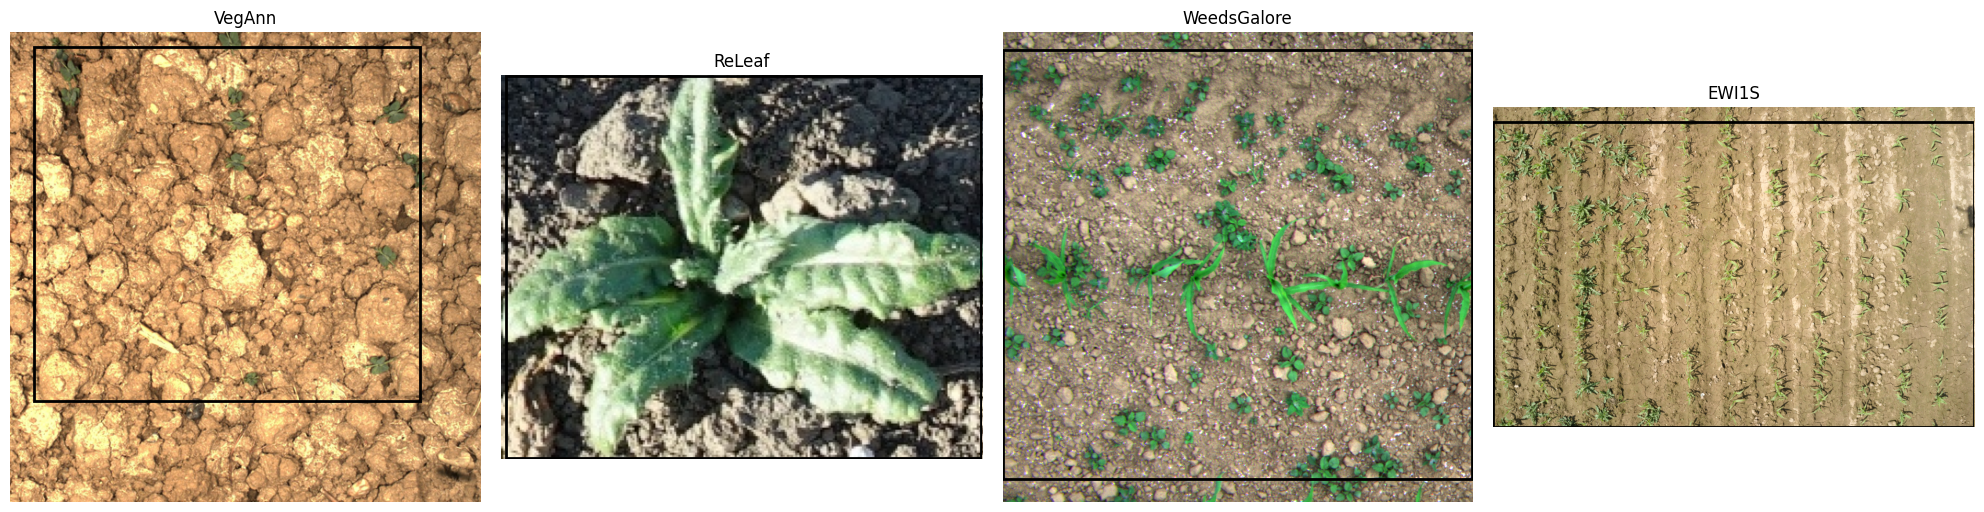

In [30]:
#Visualize one training sample from every dataset 
fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

for ax, name in zip(
    axes,
    datasets_train.keys()
):

    item = datasets_train[name][0]

    ax.imshow(
        item["image"]
    )

    x1, y1, x2, y2 = item["box"]

    rect = plt.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rect)

    ax.set_title(
        name
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [31]:
#SAM2 collate and PIL cant be stacked by default PyTorch collate 
def sam2_collate_fn(batch):

    return {
        "images": [
            item["image"]
            for item in batch
        ],

        "masks": [
            item["mask"]
            for item in batch
        ],

        "boxes": [
            item["box"]
            for item in batch
        ],

        "gt_boxes": [
            item["gt_box"]
            for item in batch
        ],

        "indices": [
            item["index"]
            for item in batch
        ],

        "datasets": [
            item["dataset"]
            for item in batch
        ]
    }


In [32]:
processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

print(
    "SAM2 processor loaded."
)

SAM2 processor loaded.


In [33]:
def prepare_sam2_batch(
    batch
):

    images = batch["images"]
    masks = batch["masks"]
    boxes = batch["boxes"]

    input_boxes = [
        [box.tolist()]
        for box in boxes
    ]

    inputs = processor(
        images=images,
        segmentation_maps=masks,
        input_boxes=input_boxes,
        return_tensors="pt"
    )

    inputs = {
        key: (
            value.to(device)
            if torch.is_tensor(value)
            else value
        )
        for key, value in inputs.items()
    }

    return inputs

In [34]:
#Loss functions 
bce_loss_fn = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    targets,
    smooth=1.0
):

    probabilities = torch.sigmoid(
        logits
    )

    probabilities = probabilities.flatten(1)

    targets = targets.flatten(1)

    intersection = (
        probabilities * targets
    ).sum(dim=1)

    dice = (
        2.0 * intersection + smooth
    ) / (
        probabilities.sum(dim=1)
        + targets.sum(dim=1)
        + smooth
    )

    return 1.0 - dice.mean()


def combined_segmentation_loss(
    logits,
    targets
):

    bce = bce_loss_fn(
        logits,
        targets
    )

    dice = dice_loss(
        logits,
        targets
    )

    total = (
        0.5 * bce
        + 0.5 * dice
    )

    return total, bce, dice

In [35]:
#extract SAM2 mask logits 
def extract_single_mask_logits(
    pred_masks
):
    """
    Convert SAM2 mask output to [B, H, W].
    """

    logits = pred_masks

    while logits.ndim > 3:
        logits = logits[:, 0]

    return logits

In [36]:
#Mtrics 
def compute_batch_metrics(
    logits,
    targets,
    threshold=0.5,
    epsilon=1e-7
):

    probabilities = torch.sigmoid(
        logits
    )

    predictions = (
        probabilities >= threshold
    ).float()

    predictions = predictions.flatten(1)
    targets = targets.flatten(1)

    intersection = (
        predictions * targets
    ).sum(dim=1)

    prediction_sum = (
        predictions.sum(dim=1)
    )

    target_sum = (
        targets.sum(dim=1)
    )

    union = (
        prediction_sum
        + target_sum
        - intersection
    )

    per_image_iou = (
        intersection + epsilon
    ) / (
        union + epsilon
    )

    per_image_dice = (
        2 * intersection + epsilon
    ) / (
        prediction_sum
        + target_sum
        + epsilon
    )

    return {
        "per_image_iou_sum":
            per_image_iou.sum().item(),

        "per_image_dice_sum":
            per_image_dice.sum().item(),

        "intersection":
            intersection.sum().item(),

        "union":
            union.sum().item(),

        "prediction_sum":
            prediction_sum.sum().item(),

        "target_sum":
            target_sum.sum().item(),

        "num_images":
            targets.shape[0]
    }

In [37]:
#USING SAM2 FINE TUNED ON VEGANN 
#Every experiment starts from existing checkpoint best_sam2_vegann_mask_decoder.pt 

def create_domain_adapted_sam2():

    model = Sam2Model.from_pretrained(
        MODEL_NAME
    )

    checkpoint = torch.load(
        VEGANN_SAM2_CHECKPOINT,
        map_location="cpu",
        weights_only=False
    )

    if (
        isinstance(checkpoint, dict)
        and "mask_decoder_state_dict"
        in checkpoint
    ):
        decoder_state = (
            checkpoint[
                "mask_decoder_state_dict"
            ]
        )

    elif isinstance(checkpoint, dict):

        decoder_state = checkpoint

    else:

        raise TypeError(
            "Unsupported checkpoint structure."
        )

    load_result = (
        model.mask_decoder.load_state_dict(
            decoder_state,
            strict=True
        )
    )

    print(
        "Loaded VegAnn decoder checkpoint."
    )

    print(
        "Original checkpoint epoch:",
        checkpoint.get(
            "epoch",
            "N/A"
        )
    )

    print(
        "Original best IoU:",
        checkpoint.get(
            "best_mean_iou",
            "N/A"
        )
    )

    # Freeze EVERYTHING
    for parameter in model.parameters():
        parameter.requires_grad = False

    # Unfreeze ONLY mask decoder
    for parameter in (
        model.mask_decoder.parameters()
    ):
        parameter.requires_grad = True

    model = model.to(device)

    return model


In [38]:
#Verify parameters 
model_check = create_domain_adapted_sam2()

total_parameters = sum(
    p.numel()
    for p in model_check.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model_check.parameters()
    if p.requires_grad
)

print(
    f"Total parameters: "
    f"{total_parameters:,}"
)

print(
    f"Trainable parameters: "
    f"{trainable_parameters:,}"
)

print(
    f"Trainable percentage: "
    f"{100 * trainable_parameters / total_parameters:.4f}%"
)

del model_check

if torch.cuda.is_available():
    torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916
Total parameters: 31,440,721
Trainable parameters: 4,215,109
Trainable percentage: 13.4065%


In [39]:
#Training function 
def train_one_epoch(
    model,
    loader,
    optimizer,
    scaler
):

    model.train()

    running_loss = 0.0
    running_bce = 0.0
    running_dice = 0.0

    for batch_index, batch in enumerate(
        loader
    ):

        inputs = prepare_sam2_batch(
            batch
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # Frozen image encoder
        with torch.no_grad():

            image_embeddings = (
                model.get_image_embeddings(
                    inputs["pixel_values"]
                )
            )

        with torch.amp.autocast(
            "cuda",
            enabled=torch.cuda.is_available()
        ):

            outputs = model(
                image_embeddings=image_embeddings,
                input_boxes=inputs["input_boxes"],
                multimask_output=False
            )

            logits = (
                extract_single_mask_logits(
                    outputs.pred_masks
                )
            )

            targets = (
                inputs["labels"]
                .float()
            )

            while targets.ndim > 3:

                targets = targets[:, 0]

            targets = F.interpolate(
                targets.unsqueeze(1),
                size=logits.shape[-2:],
                mode="nearest"
            ).squeeze(1)

            targets = (
                targets > 0
            ).float()

            loss, bce, dice = (
                combined_segmentation_loss(
                    logits,
                    targets
                )
            )

        scaler.scale(
            loss
        ).backward()

        scaler.unscale_(
            optimizer
        )

        torch.nn.utils.clip_grad_norm_(
            model.mask_decoder.parameters(),
            max_norm=1.0
        )

        scaler.step(
            optimizer
        )

        scaler.update()

        running_loss += loss.item()
        running_bce += bce.item()
        running_dice += dice.item()

        if (
            (batch_index + 1) % 100
            == 0
        ):

            print(
                f"Batch "
                f"{batch_index + 1}/"
                f"{len(loader)} | "
                f"Loss: "
                f"{running_loss / (batch_index + 1):.4f}"
            )

    n_batches = len(loader)

    return {
        "loss":
            running_loss / n_batches,

        "bce":
            running_bce / n_batches,

        "dice_loss":
            running_dice / n_batches
    }

In [40]:
#Validation function 
@torch.no_grad()
def validate(
    model,
    loader,
    threshold=0.5
):

    model.eval()

    running_loss = 0.0

    metric_totals = {
        "per_image_iou_sum": 0.0,
        "per_image_dice_sum": 0.0,
        "intersection": 0.0,
        "union": 0.0,
        "prediction_sum": 0.0,
        "target_sum": 0.0,
        "num_images": 0
    }

    for batch in loader:

        inputs = prepare_sam2_batch(
            batch
        )

        image_embeddings = (
            model.get_image_embeddings(
                inputs["pixel_values"]
            )
        )

        outputs = model(
            image_embeddings=image_embeddings,
            input_boxes=inputs["input_boxes"],
            multimask_output=False
        )

        logits = (
            extract_single_mask_logits(
                outputs.pred_masks
            )
        )

        targets = (
            inputs["labels"]
            .float()
        )

        while targets.ndim > 3:
            targets = targets[:, 0]

        targets = F.interpolate(
            targets.unsqueeze(1),
            size=logits.shape[-2:],
            mode="nearest"
        ).squeeze(1)

        targets = (
            targets > 0
        ).float()

        loss, _, _ = (
            combined_segmentation_loss(
                logits,
                targets
            )
        )

        running_loss += loss.item()

        batch_metrics = (
            compute_batch_metrics(
                logits,
                targets,
                threshold=threshold
            )
        )

        for key in metric_totals:
            if key in batch_metrics:
                metric_totals[key] += (
                    batch_metrics[key]
                )

    mean_iou = (
        metric_totals[
            "per_image_iou_sum"
        ]
        /
        metric_totals[
            "num_images"
        ]
    )

    mean_dice = (
        metric_totals[
            "per_image_dice_sum"
        ]
        /
        metric_totals[
            "num_images"
        ]
    )

    global_iou = (
        metric_totals[
            "intersection"
        ]
        /
        (
            metric_totals[
                "union"
            ]
            + 1e-7
        )
    )

    global_dice = (
        2
        * metric_totals[
            "intersection"
        ]
        /
        (
            metric_totals[
                "prediction_sum"
            ]
            +
            metric_totals[
                "target_sum"
            ]
            + 1e-7
        )
    )

    return {
        "loss":
            running_loss / len(loader),

        "mean_iou":
            mean_iou,

        "mean_dice":
            mean_dice,

        "global_iou":
            global_iou,

        "global_dice":
            global_dice
    }

In [41]:
#DeBug one batch 

debug_dataset = datasets_train["ReLeaf"]

debug_loader = DataLoader(
    debug_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=0,
    collate_fn=sam2_collate_fn
)

debug_batch = next(
    iter(debug_loader)
)

debug_inputs = prepare_sam2_batch(
    debug_batch
)

print(
    "Processor keys:",
    debug_inputs.keys()
)

for key, value in debug_inputs.items():

    if torch.is_tensor(value):

        print(
            key,
            "| shape:",
            value.shape,
            "| dtype:",
            value.dtype
        )

Processor keys: dict_keys(['pixel_values', 'original_sizes', 'labels', 'input_boxes'])
pixel_values | shape: torch.Size([1, 3, 1024, 1024]) | dtype: torch.float32
original_sizes | shape: torch.Size([1, 2]) | dtype: torch.int64
labels | shape: torch.Size([1, 256, 256]) | dtype: torch.int64
input_boxes | shape: torch.Size([1, 1, 4]) | dtype: torch.float32


In [42]:
#Debug SAM2 forward pass 
debug_model = create_domain_adapted_sam2()

debug_model.eval()

with torch.no_grad():

    image_embeddings = (
        debug_model.get_image_embeddings(
            debug_inputs["pixel_values"]
        )
    )

    outputs = debug_model(
        image_embeddings=image_embeddings,
        input_boxes=debug_inputs["input_boxes"],
        multimask_output=False
    )

logits = (
    extract_single_mask_logits(
        outputs.pred_masks
    )
)

targets = (
    debug_inputs["labels"]
    .float()
)

while targets.ndim > 3:
    targets = targets[:, 0]

targets = F.interpolate(
    targets.unsqueeze(1),
    size=logits.shape[-2:],
    mode="nearest"
).squeeze(1)

targets = (
    targets > 0
).float()

loss, bce, dice = (
    combined_segmentation_loss(
        logits,
        targets
    )
)

print(
    "Predicted logits:",
    logits.shape
)

print(
    "Targets:",
    targets.shape
)

print(
    "Total loss:",
    loss.item()
)

print(
    "BCE:",
    bce.item()
)

print(
    "Dice loss:",
    dice.item()
)

del debug_model

if torch.cuda.is_available():
    torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916
Predicted logits: torch.Size([1, 256, 256])
Targets: torch.Size([1, 256, 256])
Total loss: 0.07899056375026703
BCE: 0.11916366219520569
Dice loss: 0.03881746530532837


In [43]:
def run_finetuning_experiment(
    experiment_name,
    train_dataset,
    val_dataset,
    num_epochs=NUM_EPOCHS,
    learning_rate=LEARNING_RATE,
    patience=EARLY_STOPPING_PATIENCE
):

    print("\n" + "=" * 70)
    print(
        f"STARTING EXPERIMENT: "
        f"{experiment_name}"
    )
    print("=" * 70)

    experiment_dir = (
        DOMAIN_FT_ROOT
        / experiment_name
    )

    experiment_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    best_checkpoint_path = (
        experiment_dir
        / "best_mask_decoder.pt"
    )

    history_csv_path = (
        experiment_dir
        / "training_history.csv"
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn
    )

    print(
        "Training samples:",
        len(train_dataset)
    )

    print(
        "Validation samples:",
        len(val_dataset)
    )

    model = (
        create_domain_adapted_sam2()
    )

    optimizer = torch.optim.AdamW(
        [
            p
            for p in model.parameters()
            if p.requires_grad
        ],
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    history = {
        "epoch": [],
        "train_loss": [],
        "train_bce": [],
        "train_dice_loss": [],
        "val_loss": [],
        "mean_iou": [],
        "mean_dice": [],
        "global_iou": [],
        "global_dice": []
    }

    best_mean_iou = -1.0
    epochs_without_improvement = 0

    for epoch in range(
        num_epochs
    ):

        print("\n" + "-" * 70)
        print(
            f"Epoch "
            f"{epoch + 1}/{num_epochs}"
        )
        print("-" * 70)

        train_results = (
            train_one_epoch(
                model=model,
                loader=train_loader,
                optimizer=optimizer,
                scaler=scaler
            )
        )

        val_results = (
            validate(
                model=model,
                loader=val_loader,
                threshold=MASK_THRESHOLD
            )
        )

        history["epoch"].append(
            epoch + 1
        )

        history["train_loss"].append(
            train_results["loss"]
        )

        history["train_bce"].append(
            train_results["bce"]
        )

        history["train_dice_loss"].append(
            train_results["dice_loss"]
        )

        history["val_loss"].append(
            val_results["loss"]
        )

        history["mean_iou"].append(
            val_results["mean_iou"]
        )

        history["mean_dice"].append(
            val_results["mean_dice"]
        )

        history["global_iou"].append(
            val_results["global_iou"]
        )

        history["global_dice"].append(
            val_results["global_dice"]
        )

        print(
            f"Train Loss: "
            f"{train_results['loss']:.4f}"
        )

        print(
            f"Val Loss: "
            f"{val_results['loss']:.4f}"
        )

        print(
            f"Mean IoU: "
            f"{100 * val_results['mean_iou']:.2f}%"
        )

        print(
            f"Mean Dice: "
            f"{100 * val_results['mean_dice']:.2f}%"
        )

        print(
            f"Global IoU: "
            f"{100 * val_results['global_iou']:.2f}%"
        )

        print(
            f"Global Dice: "
            f"{100 * val_results['global_dice']:.2f}%"
        )

        # ------------------------------------
        # Best checkpoint
        # ------------------------------------

        if (
            val_results["mean_iou"]
            > best_mean_iou
        ):

            best_mean_iou = (
                val_results["mean_iou"]
            )

            epochs_without_improvement = 0

            torch.save(
                {
                    "experiment_name":
                        experiment_name,

                    "epoch":
                        epoch + 1,

                    "model_name":
                        MODEL_NAME,

                    "starting_checkpoint":
                        str(
                            VEGANN_SAM2_CHECKPOINT
                        ),

                    "train_samples":
                        len(train_dataset),

                    "val_samples":
                        len(val_dataset),

                    "learning_rate":
                        learning_rate,

                    "box_jitter_fraction":
                        BOX_JITTER_FRACTION,

                    "mask_decoder_state_dict":
                        model.mask_decoder.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "best_mean_iou":
                        best_mean_iou,

                    "history":
                        history
                },
                best_checkpoint_path
            )

            print(
                "\n*** New BEST checkpoint saved ***"
            )

            print(
                best_checkpoint_path
            )

        else:

            epochs_without_improvement += 1

            print(
                f"No improvement for "
                f"{epochs_without_improvement} epoch(s)."
            )

        # ------------------------------------
        # Save history after EVERY epoch
        # ------------------------------------

        pd.DataFrame(
            history
        ).to_csv(
            history_csv_path,
            index=False
        )

        # ------------------------------------
        # Early stopping
        # ------------------------------------

        if (
            epochs_without_improvement
            >= patience
        ):

            print(
                "\nEarly stopping triggered."
            )

            break

    # ----------------------------------------
    # Final plots
    # ----------------------------------------

    history_df = pd.DataFrame(
        history
    )

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"{experiment_name} — Loss"
    )

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir
        / "loss_curve.png",
        dpi=200
    )

    plt.show()

    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["mean_iou"] * 100,
        label="Mean IoU"
    )

    plt.plot(
        history_df["epoch"],
        history_df["mean_dice"] * 100,
        label="Mean Dice"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Score (%)")

    plt.title(
        f"{experiment_name} — Per-image Metrics"
    )

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir
        / "metrics_curve.png",
        dpi=200
    )

    plt.show()

    print("\n" + "=" * 70)
    print(
        f"FINISHED: {experiment_name}"
    )
    print("=" * 70)

    print(
        f"Best Mean IoU: "
        f"{100 * best_mean_iou:.2f}%"
    )

    print(
        "Best checkpoint:",
        best_checkpoint_path
    )

    return {
        "experiment_name":
            experiment_name,

        "best_mean_iou":
            best_mean_iou,

        "checkpoint":
            best_checkpoint_path,

        "history":
            history_df
    }

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



STARTING EXPERIMENT: VegAnn_to_ReLeaf
Training samples: 276
Validation samples: 34


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1321
Batch 200/276 | Loss: 0.1249
Train Loss: 0.1262
Val Loss: 0.1177
Mean IoU: 83.91%
Mean Dice: 91.05%
Global IoU: 84.85%
Global Dice: 91.80%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/276 | Loss: 0.1016
Batch 200/276 | Loss: 0.1035
Train Loss: 0.1046
Val Loss: 0.1195
Mean IoU: 83.68%
Mean Dice: 90.81%
Global IoU: 84.93%
Global Dice: 91.85%
No improvement for 1 epoch(s).

----------------------------------------------------------------------
Epoch 3/10
--------------------

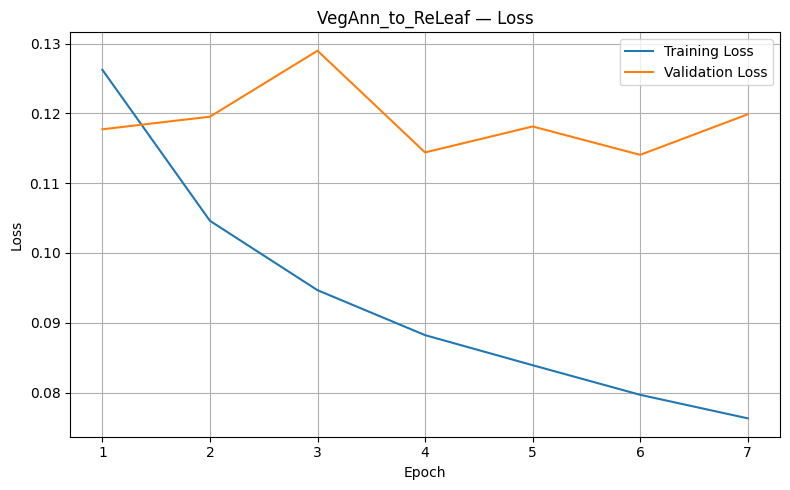

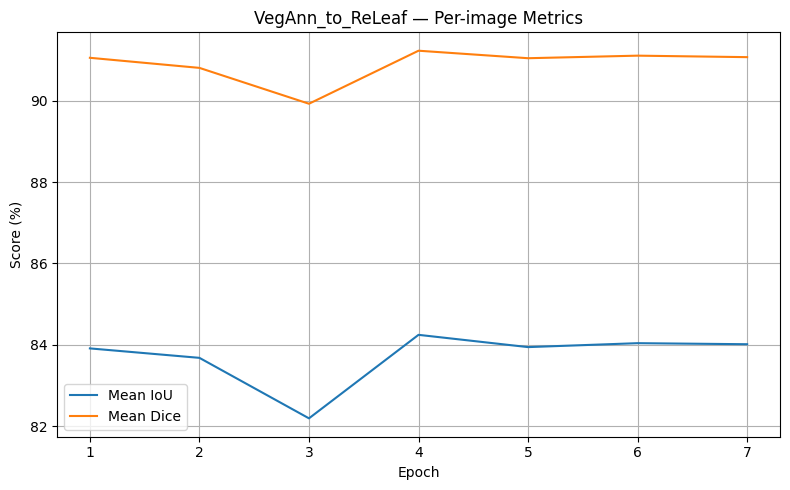


FINISHED: VegAnn_to_ReLeaf
Best Mean IoU: 84.24%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt


In [44]:
#RELEAF FINE TUNING 
releaf_result = run_finetuning_experiment(
    experiment_name="VegAnn_to_ReLeaf",

    train_dataset=datasets_train["ReLeaf"],

    val_dataset=datasets_val["ReLeaf"],

    num_epochs=NUM_EPOCHS,

    learning_rate=LEARNING_RATE,

    patience=EARLY_STOPPING_PATIENCE
)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



STARTING EXPERIMENT: VegAnn_to_WeedsGalore
Training samples: 124
Validation samples: 15


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1703
Train Loss: 0.1678
Val Loss: 0.1550
Mean IoU: 64.39%
Mean Dice: 78.02%
Global IoU: 69.75%
Global Dice: 82.18%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Batch 100/124 | Loss: 0.1574
Train Loss: 0.1581
Val Loss: 0.1539
Mean IoU: 64.49%
Mean Dice: 78.12%
Global IoU: 69.04%
Global Dice: 81.69%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt

------------------------------------------------------------

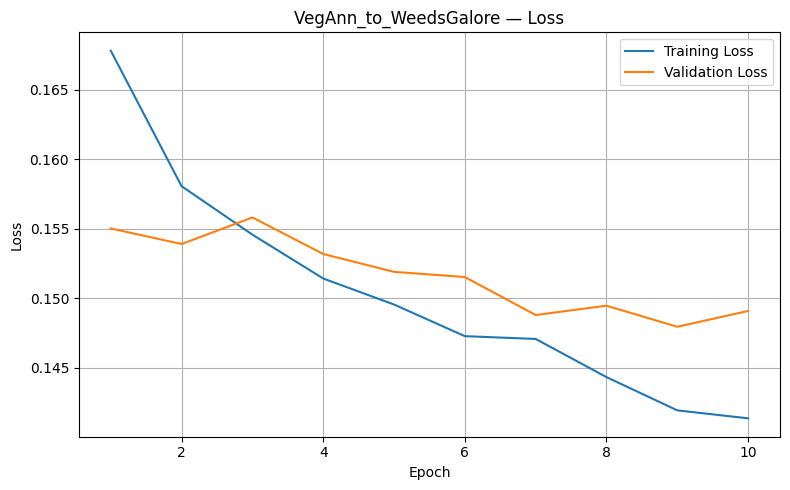

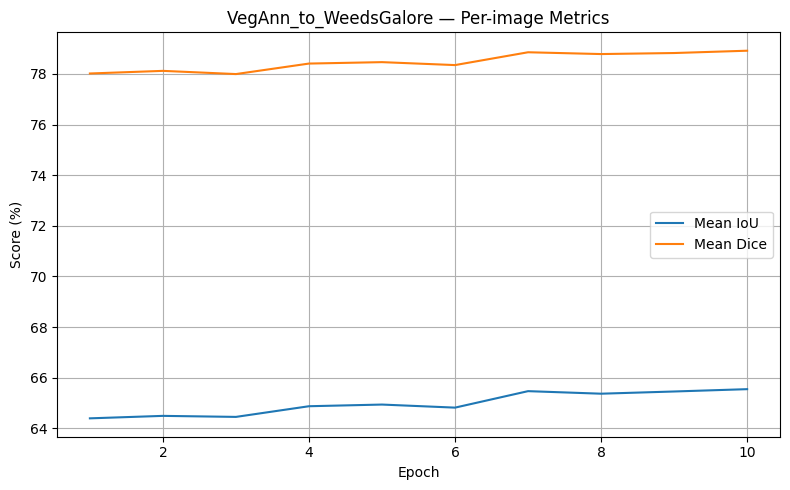


FINISHED: VegAnn_to_WeedsGalore
Best Mean IoU: 65.55%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt


In [45]:
#WEEDSGALORE FINE TUNING 
weedsgalore_result = run_finetuning_experiment(
    experiment_name="VegAnn_to_WeedsGalore",

    train_dataset=datasets_train["WeedsGalore"],

    val_dataset=datasets_val["WeedsGalore"],

    num_epochs=NUM_EPOCHS,

    learning_rate=LEARNING_RATE,

    patience=EARLY_STOPPING_PATIENCE
)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



STARTING EXPERIMENT: VegAnn_to_EWI1S
Training samples: 70
Validation samples: 8


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

----------------------------------------------------------------------
Epoch 1/10
----------------------------------------------------------------------
Train Loss: 0.4587
Val Loss: 0.4047
Mean IoU: 18.04%
Mean Dice: 25.33%
Global IoU: 17.79%
Global Dice: 30.21%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 2/10
----------------------------------------------------------------------
Train Loss: 0.3915
Val Loss: 0.3777
Mean IoU: 22.03%
Mean Dice: 30.16%
Global IoU: 26.07%
Global Dice: 41.36%

*** New BEST checkpoint saved ***
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt

----------------------------------------------------------------------
Epoch 3/10
------------------------------------------------

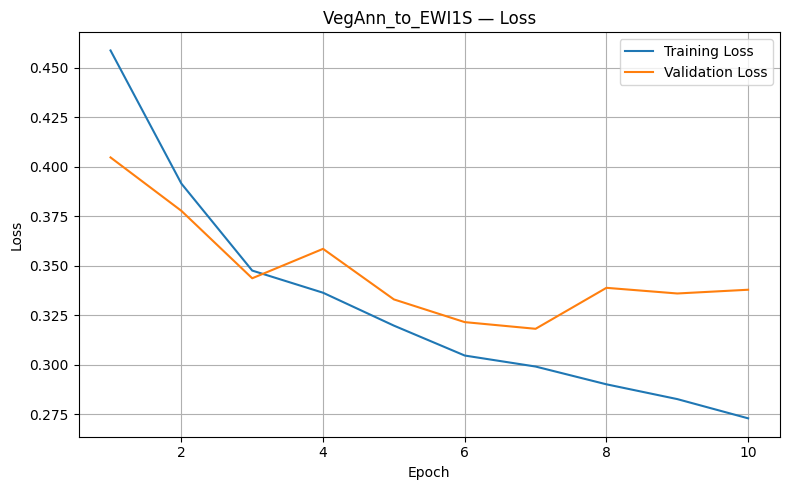

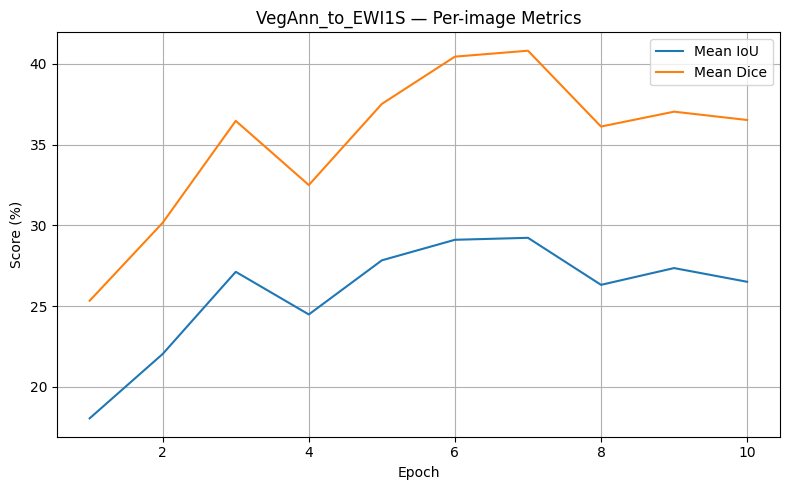


FINISHED: VegAnn_to_EWI1S
Best Mean IoU: 29.22%
Best checkpoint: /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt


In [46]:
#EWIS1 fine tuning 
ewis1_result = run_finetuning_experiment(
    experiment_name="VegAnn_to_EWI1S",

    train_dataset=datasets_train["EWI1S"],

    val_dataset=datasets_val["EWI1S"],

    num_epochs=NUM_EPOCHS,

    learning_rate=LEARNING_RATE,

    patience=EARLY_STOPPING_PATIENCE
)

In [58]:
#Build Joint training Dataset 
joint_train_dataset = ConcatDataset(
    [
        datasets_train["VegAnn"],
        datasets_train["ReLeaf"],
        datasets_train["WeedsGalore"],
        datasets_train["EWI1S"]
    ]
)

print(
    "Total joint training samples:",
    len(joint_train_dataset)
)

Total joint training samples: 3436


In [59]:
#Build balanced sampler 
dataset_lengths = [
    len(datasets_train["VegAnn"]),
    len(datasets_train["ReLeaf"]),
    len(datasets_train["WeedsGalore"]),
    len(datasets_train["EWI1S"])
]

dataset_names = [
    "VegAnn",
    "ReLeaf",
    "WeedsGalore",
    "EWI1S"
]

print(
    dict(
        zip(
            dataset_names,
            dataset_lengths
        )
    )
)

{'VegAnn': 2966, 'ReLeaf': 276, 'WeedsGalore': 124, 'EWI1S': 70}


In [60]:
#Inverse frequency weights 
sample_weights = []

for length in dataset_lengths:

    weight = 1.0 / length

    sample_weights.extend(
        [weight] * length
    )

sample_weights = torch.tensor(
    sample_weights,
    dtype=torch.double
)

total_joint_samples = (
    JOINT_SAMPLES_PER_DATASET
    * len(dataset_names)
)

joint_sampler = WeightedRandomSampler(
    weights=sample_weights,

    num_samples=total_joint_samples,

    replacement=True,

    generator=torch.Generator().manual_seed(
        SEED
    )
)

print(
    "Samples per joint epoch:",
    total_joint_samples
)

Samples per joint epoch: 2000


In [61]:
#Joint validation set 
joint_val_datasets = {
    "VegAnn":
        datasets_val["VegAnn"],

    "ReLeaf":
        datasets_val["ReLeaf"],

    "WeedsGalore":
        datasets_val["WeedsGalore"],

    "EWI1S":
        datasets_val["EWI1S"]
}

print(
    "Joint validation datasets created."
)

Joint validation datasets created.


In [62]:
#Joint training function 
def run_joint_finetuning():

    experiment_name = (
        "VegAnn_ReLeaf_WeedsGalore_EWI1S"
    )

    experiment_dir = (
        DOMAIN_FT_ROOT
        / experiment_name
    )

    experiment_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    best_checkpoint_path = (
        experiment_dir
        / "best_mask_decoder.pt"
    )

    history_csv_path = (
        experiment_dir
        / "training_history.csv"
    )

    train_loader = DataLoader(
        joint_train_dataset,
        batch_size=BATCH_SIZE,
        sampler=joint_sampler,
        num_workers=NUM_WORKERS,
        pin_memory=True,
        collate_fn=sam2_collate_fn
    )

    print(
        "Joint training samples/epoch:",
        len(train_loader)
    )

    model = create_domain_adapted_sam2()

    optimizer = torch.optim.AdamW(
        [
            p
            for p in model.parameters()
            if p.requires_grad
        ],
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=torch.cuda.is_available()
    )

    history = {
        "epoch": [],
        "train_loss": [],

        "VegAnn_iou": [],
        "ReLeaf_iou": [],
        "WeedsGalore_iou": [],
        "EWI1S_iou": [],

        "VegAnn_dice": [],
        "ReLeaf_dice": [],
        "WeedsGalore_dice": [],
        "EWI1S_dice": [],

        "mean_all_dataset_iou": []
    }

    best_joint_iou = -1.0

    epochs_without_improvement = 0

    for epoch in range(
        NUM_EPOCHS
    ):

        print("\n" + "=" * 70)

        print(
            f"JOINT EPOCH "
            f"{epoch + 1}/{NUM_EPOCHS}"
        )

        print("=" * 70)

        train_results = train_one_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            scaler=scaler
        )

        history["epoch"].append(
            epoch + 1
        )

        history["train_loss"].append(
            train_results["loss"]
        )

        dataset_ious = []

        # ----------------------------------------
        # Validate separately on each dataset
        # ----------------------------------------

        for dataset_name, val_dataset in (
            joint_val_datasets.items()
        ):

            val_loader = DataLoader(
                val_dataset,
                batch_size=BATCH_SIZE,
                shuffle=False,
                num_workers=NUM_WORKERS,
                pin_memory=True,
                collate_fn=sam2_collate_fn
            )

            val_results = validate(
                model=model,
                loader=val_loader,
                threshold=MASK_THRESHOLD
            )

            iou_percent = (
                100 * val_results["mean_iou"]
            )

            dice_percent = (
                100 * val_results["mean_dice"]
            )

            print(
                f"{dataset_name:15s} | "
                f"IoU: {iou_percent:.2f}% | "
                f"Dice: {dice_percent:.2f}%"
            )

            history[
                f"{dataset_name}_iou"
            ].append(
                val_results["mean_iou"]
            )

            history[
                f"{dataset_name}_dice"
            ].append(
                val_results["mean_dice"]
            )

            dataset_ious.append(
                val_results["mean_iou"]
            )

        joint_mean_iou = float(
            np.mean(dataset_ious)
        )

        history[
            "mean_all_dataset_iou"
        ].append(
            joint_mean_iou
        )

        print(
            f"\nMean IoU across 4 datasets: "
            f"{100 * joint_mean_iou:.2f}%"
        )

        # ----------------------------------------
        # Save best model
        # ----------------------------------------

        if (
            joint_mean_iou
            > best_joint_iou
        ):

            best_joint_iou = (
                joint_mean_iou
            )

            epochs_without_improvement = 0

            torch.save(
                {
                    "experiment_name":
                        experiment_name,

                    "epoch":
                        epoch + 1,

                    "model_name":
                        MODEL_NAME,

                    "starting_checkpoint":
                        str(
                            VEGANN_SAM2_CHECKPOINT
                        ),

                    "datasets":
                        [
                            "VegAnn",
                            "ReLeaf",
                            "WeedsGalore",
                            "EWI1S"
                        ],

                    "samples_per_dataset_per_epoch":
                        JOINT_SAMPLES_PER_DATASET,

                    "learning_rate":
                        LEARNING_RATE,

                    "box_jitter_fraction":
                        BOX_JITTER_FRACTION,

                    "mask_decoder_state_dict":
                        model.mask_decoder.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "best_mean_iou":
                        best_joint_iou,

                    "history":
                        history
                },
                best_checkpoint_path
            )

            print(
                "\n*** BEST JOINT CHECKPOINT SAVED ***"
            )

            print(
                best_checkpoint_path
            )

        else:

            epochs_without_improvement += 1

            print(
                "No joint improvement for",
                epochs_without_improvement,
                "epoch(s)."
            )

        # Save history every epoch

        pd.DataFrame(
            history
        ).to_csv(
            history_csv_path,
            index=False
        )

        if (
            epochs_without_improvement
            >= EARLY_STOPPING_PATIENCE
        ):

            print(
                "\nJoint training early stopped."
            )

            break

    # ----------------------------------------
    # Plot joint IoU
    # ----------------------------------------

    history_df = pd.DataFrame(
        history
    )

    plt.figure(
        figsize=(10, 6)
    )

    for dataset_name in [
        "VegAnn",
        "ReLeaf",
        "WeedsGalore",
        "EWI1S"
    ]:

        plt.plot(
            history_df["epoch"],
            history_df[
                f"{dataset_name}_iou"
            ] * 100,
            label=dataset_name
        )

    plt.xlabel("Epoch")
    plt.ylabel("Mean IoU (%)")

    plt.title(
        "Joint SAM2 Fine-Tuning — Validation IoU"
    )

    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    plt.savefig(
        experiment_dir
        / "joint_iou_curve.png",
        dpi=200
    )

    plt.show()

    return {
        "checkpoint":
            best_checkpoint_path,

        "best_mean_iou":
            best_joint_iou,

        "history":
            history_df
    }

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Joint training samples/epoch: 2000


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded VegAnn decoder checkpoint.
Original checkpoint epoch: 8
Original best IoU: 0.8724805513351916

JOINT EPOCH 1/10
Batch 100/2000 | Loss: 0.1916
Batch 200/2000 | Loss: 0.2086
Batch 300/2000 | Loss: 0.2100
Batch 400/2000 | Loss: 0.2028
Batch 500/2000 | Loss: 0.2032
Batch 600/2000 | Loss: 0.2032
Batch 700/2000 | Loss: 0.2021
Batch 800/2000 | Loss: 0.1971
Batch 900/2000 | Loss: 0.1954
Batch 1000/2000 | Loss: 0.1932
Batch 1100/2000 | Loss: 0.1930
Batch 1200/2000 | Loss: 0.1923
Batch 1300/2000 | Loss: 0.1918
Batch 1400/2000 | Loss: 0.1899
Batch 1500/2000 | Loss: 0.1885
Batch 1600/2000 | Loss: 0.1874
Batch 1700/2000 | Loss: 0.1871
Batch 1800/2000 | Loss: 0.1870
Batch 1900/2000 | Loss: 0.1866
Batch 2000/2000 | Loss: 0.1863
VegAnn          | IoU: 86.76% | Dice: 92.45%
ReLeaf          | IoU: 83.73% | Dice: 90.91%
WeedsGalore     | IoU: 63.89% | Dice: 77.65%
EWI1S           | IoU: 23.84% | Dice: 31.96%

Mean IoU across 4 datasets: 64.55%

*** BEST JOINT CHECKPOINT SAVED ***
/home/zahranadeem

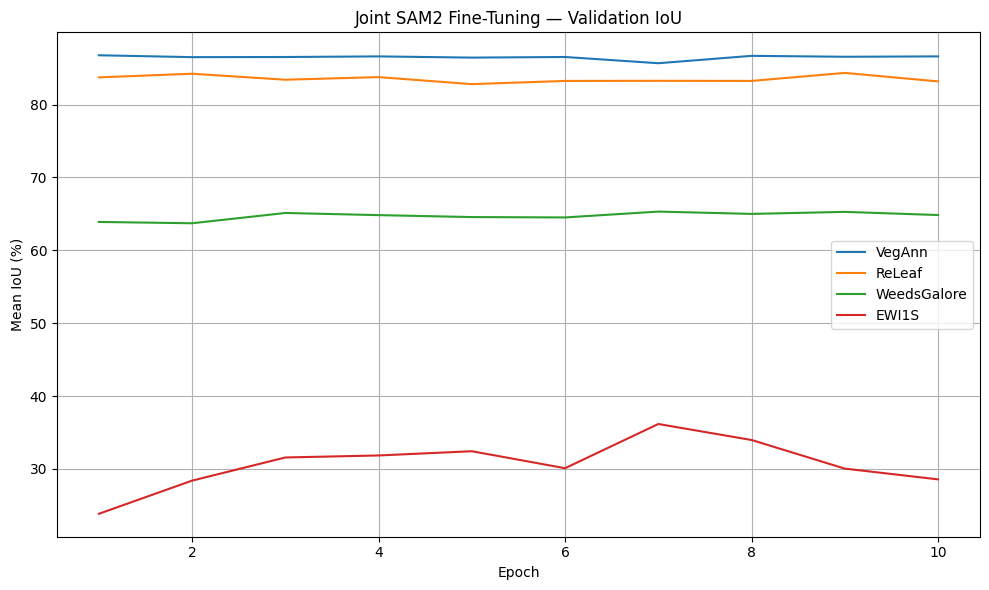

In [63]:
#Joint Experiment 
joint_result = run_joint_finetuning()

In [64]:
#Check all checkpoints exist 
checkpoint_paths = {
    "ReLeaf":
        DOMAIN_FT_ROOT
        / "VegAnn_to_ReLeaf"
        / "best_mask_decoder.pt",

    "WeedsGalore":
        DOMAIN_FT_ROOT
        / "VegAnn_to_WeedsGalore"
        / "best_mask_decoder.pt",

    "EWI1S":
        DOMAIN_FT_ROOT
        / "VegAnn_to_EWI1S"
        / "best_mask_decoder.pt",

    "All 4 datasets":
        DOMAIN_FT_ROOT
        / "VegAnn_ReLeaf_WeedsGalore_EWI1S"
        / "best_mask_decoder.pt"
}

for name, path in checkpoint_paths.items():

    print(
        f"{name:20s}: "
        f"{'SAVED' if path.exists() else 'MISSING'}"
    )

    if path.exists():
        print(
            "   ",
            path
        )

ReLeaf              : SAVED
    /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt
WeedsGalore         : SAVED
    /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt
EWI1S               : SAVED
    /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt
All 4 datasets      : SAVED
    /home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt


In [65]:
#Best results from individual experiments 
individual_results = []

for name, result in [
    ("ReLeaf", releaf_result),
    ("WeedsGalore", weedsgalore_result),
    ("EWI1S", ewis1_result)
]:

    history_df = result["history"]

    best_row = history_df.loc[
        history_df["mean_iou"].idxmax()
    ]

    individual_results.append(
        {
            "Experiment": name,

            "Best Epoch":
                int(best_row["epoch"]),

            "Mean IoU (%)":
                100 * best_row["mean_iou"],

            "Mean Dice (%)":
                100 * best_row["mean_dice"],

            "Global IoU (%)":
                100 * best_row["global_iou"],

            "Global Dice (%)":
                100 * best_row["global_dice"]
        }
    )

individual_summary = pd.DataFrame(
    individual_results
)

individual_summary

,Experiment,Best Epoch,Mean IoU (%),Mean Dice (%),Global IoU (%),Global Dice (%)
0,ReLeaf,4,84.242278,91.228143,85.251028,92.038386
1,WeedsGalore,10,65.545718,78.918774,70.442038,82.658057
2,EWI1S,7,29.224663,40.815455,38.361030,55.450628


In [66]:
#Save summary 
summary_rows = []

for name, result in [
    ("ReLeaf", releaf_result),
    ("WeedsGalore", weedsgalore_result),
    ("EWI1S", ewis1_result)
]:

    history_df = result["history"]

    best_row = history_df.loc[
        history_df["mean_iou"].idxmax()
    ]

    summary_rows.append(
        {
            "Experiment":
                name,

            "Training_Data":
                name,

            "Best_Epoch":
                int(best_row["epoch"]),

            "Best_Mean_IoU":
                float(
                    best_row["mean_iou"]
                ),

            "Best_Mean_Dice":
                float(
                    best_row["mean_dice"]
                ),

            "Global_IoU":
                float(
                    best_row["global_iou"]
                ),

            "Global_Dice":
                float(
                    best_row["global_dice"]
                ),

            "Checkpoint":
                str(
                    checkpoint_paths[name]
                )
        }
    )


# Add joint experiment
joint_history = joint_result["history"]

best_joint_row = joint_history.loc[
    joint_history[
        "mean_all_dataset_iou"
    ].idxmax()
]

summary_rows.append(
    {
        "Experiment":
            "All 4 datasets",

        "Training_Data":
            "VegAnn + ReLeaf + "
            "WeedsGalore + EWI1S",

        "Best_Epoch":
            int(
                best_joint_row["epoch"]
            ),

        "Best_Mean_IoU":
            float(
                best_joint_row[
                    "mean_all_dataset_iou"
                ]
            ),

        "Best_Mean_Dice":
            np.nan,

        "Global_IoU":
            np.nan,

        "Global_Dice":
            np.nan,

        "Checkpoint":
            str(
                checkpoint_paths[
                    "All 4 datasets"
                ]
            )
    }
)

master_summary = pd.DataFrame(
    summary_rows
)

MASTER_SUMMARY_PATH = (
    DOMAIN_FT_ROOT
    / "domain_finetuning_summary.csv"
)

master_summary.to_csv(
    MASTER_SUMMARY_PATH,
    index=False
)

print(
    "Saved:",
    MASTER_SUMMARY_PATH
)

master_summary

Saved: /home/zahranadeem/thesis/sam2_domain_finetuning/domain_finetuning_summary.csv


,Experiment,Training_Data,Best_Epoch,Best_Mean_IoU,Best_Mean_Dice,Global_IoU,Global_Dice,Checkpoint
0,ReLeaf,ReLeaf,4,0.842423,0.912281,0.85251,0.920384,/home/zahranadeem/thesis/sam2_domain_finetunin...
1,WeedsGalore,WeedsGalore,10,0.655457,0.789188,0.70442,0.826581,/home/zahranadeem/thesis/sam2_domain_finetunin...
2,EWI1S,EWI1S,7,0.292247,0.408155,0.38361,0.554506,/home/zahranadeem/thesis/sam2_domain_finetunin...
3,All 4 datasets,VegAnn + ReLeaf + WeedsGalore + EWI1S,7,0.675981,NaN,NaN,NaN,/home/zahranadeem/thesis/sam2_domain_finetunin...


In [67]:
#Final Dataset split report 
split_report = pd.DataFrame(
    [
        {
            "Dataset":
                "VegAnn",

            "Train":
                len(datasets_train["VegAnn"]),

            "Validation":
                len(datasets_val["VegAnn"]),

            "Test":
                "Existing VegAnn validation used later"
        },

        {
            "Dataset":
                "ReLeaf",

            "Train":
                len(releaf_train_pairs),

            "Validation":
                len(releaf_val_pairs),

            "Test":
                len(releaf_test_pairs)
        },

        {
            "Dataset":
                "WeedsGalore",

            "Train":
                len(weedsgalore_train_pairs),

            "Validation":
                len(weedsgalore_val_pairs),

            "Test":
                len(weedsgalore_test_pairs)
        },

        {
            "Dataset":
                "EWI1S",

            "Train":
                len(ewis1_train_pairs),

            "Validation":
                len(ewis1_val_pairs),

            "Test":
                len(ewis1_test_pairs)
        }
    ]
)

split_report

,Dataset,Train,Validation,Test
0,VegAnn,2966,746,Existing VegAnn validation used later
1,ReLeaf,276,34,35
2,WeedsGalore,124,15,17
3,EWI1S,70,8,10


In [68]:
#Save actual test file lists 
TEST_SPLIT_DIR = (
    DOMAIN_FT_ROOT
    / "test_splits"
)

TEST_SPLIT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def save_test_names(
    pairs,
    path
):

    names = []

    for item in pairs:

        if "image_path" in item:
            names.append(
                item["image_path"].name
            )

    pd.DataFrame(
        {"file_name": names}
    ).to_csv(
        path,
        index=False
    )


save_test_names(
    releaf_test_pairs,
    TEST_SPLIT_DIR
    / "releaf_test.csv"
)

save_test_names(
    weedsgalore_test_pairs,
    TEST_SPLIT_DIR
    / "weedsgalore_test.csv"
)

save_test_names(
    ewis1_test_pairs,
    TEST_SPLIT_DIR
    / "ewis1_test.csv"
)

print(
    "Test split manifests saved to:",
    TEST_SPLIT_DIR
)

Test split manifests saved to: /home/zahranadeem/thesis/sam2_domain_finetuning/test_splits


# LABELLED DATA EXPERIMENTS

In [ ]:
# ============================================================
# PHASE 0 — CREATE LABELLED DATA SUBSETS
# ============================================================

def create_labelled_subsets(
    train_pairs,
    fractions=(0.10,),
    seed=42
):
    """
    Create deterministic labelled subsets from a fixed
    training pool.

    The same seed ensures reproducibility.
    """

    train_pairs = list(train_pairs)

    subsets = {}

    for fraction in fractions:

        n = max(
            1,
            round(len(train_pairs) * fraction)
        )

        rng = random.Random(seed)

        selected = rng.sample(
            train_pairs,
            min(n, len(train_pairs))
        )

        subsets[f"{int(fraction * 100)}pct"] = selected

    return subsets

In [ ]:
# ============================================================
# PHASE 0 — SELECT ~10% LABELLED DATA
# ============================================================

releaf_subsets = create_labelled_subsets(
    releaf_train_pairs,
    fractions=(0.10,),
    seed=SEED
)

weedsgalore_subsets = create_labelled_subsets(
    weedsgalore_train_pairs,
    fractions=(0.10,),
    seed=SEED
)

ewis1_subsets = create_labelled_subsets(
    ewis1_train_pairs,
    fractions=(0.10,),
    seed=SEED
)

releaf_train_phase0 = releaf_subsets["10pct"]
weedsgalore_train_phase0 = weedsgalore_subsets["10pct"]
ewis1_train_phase0 = ewis1_subsets["10pct"]

print("Phase 0 labelled images:")
print("ReLeaf      :", len(releaf_train_phase0))
print("WeedsGalore :", len(weedsgalore_train_phase0))
print("EWI1S       :", len(ewis1_train_phase0))

# AGRICLIP + FINETUNED SAM2 EXPERIMENTS

In [69]:
# ============================================================
# Cell 1 — Decoder checkpoints
# ============================================================

PROJECT_ROOT = "/home/zahranadeem/thesis"

CHECKPOINTS = {
    "VegAnn_Baseline": 
        f"{PROJECT_ROOT}/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt",

    "ReLeaf_Finetuned": 
        f"{PROJECT_ROOT}/sam2_domain_finetuning/ReLeaf/best_mask_decoder.pt",

    "WeedsGalore_Finetuned": 
        f"{PROJECT_ROOT}/sam2_domain_finetuning/WeedsGalore/best_mask_decoder.pt",

    "EWI1S_Finetuned": 
        f"{PROJECT_ROOT}/sam2_domain_finetuning/EWI1S/best_mask_decoder.pt",

    "Joint_Finetuned": 
        f"{PROJECT_ROOT}/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt",
}

for name, path in CHECKPOINTS.items():
    print(f"{name}:")
    print(path)
    print("Exists:", os.path.exists(path))
    print()

VegAnn_Baseline:
/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
Exists: True

ReLeaf_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/ReLeaf/best_mask_decoder.pt
Exists: False

WeedsGalore_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/WeedsGalore/best_mask_decoder.pt
Exists: False

EWI1S_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/EWI1S/best_mask_decoder.pt
Exists: False

Joint_Finetuned:
/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt
Exists: True



In [ ]:
# ============================================================
# Cell 2 —  full pipeline identical for every checkpoint
# ============================================================

TOP_K = 32
BOX_MARGIN = 25
MASK_THRESHOLD = 0.5

print("TOP_K:", TOP_K)
print("BOX_MARGIN:", BOX_MARGIN)
print("MASK_THRESHOLD:", MASK_THRESHOLD)

TOP_K: 32
BOX_MARGIN: 25
MASK_THRESHOLD: 0.5


In [71]:
# ============================================================
# Cell 3 — Verify frozen AgriCLIP aligner
# ============================================================

print("AgriCLIP aligner:", type(releaf_adapter).__name__ if "releaf_adapter" in globals() else "Check variable name")

if "releaf_adapter" in globals():
    releaf_adapter.eval()

    trainable = sum(
        p.numel() for p in releaf_adapter.parameters() if p.requires_grad
    )
    total = sum(
        p.numel() for p in releaf_adapter.parameters()
    )

    print("Total aligner parameters:", total)
    print("Trainable aligner parameters:", trainable)

AgriCLIP aligner: Check variable name


In [72]:
# ============================================================
# Cell 4 — Fresh SAM2 model creator
# ============================================================

MODEL_NAME = "facebook/sam2.1-hiera-tiny"

def create_fresh_sam2():
    model = Sam2Model.from_pretrained(MODEL_NAME)
    model.to(DEVICE)
    model.eval()
    return model

print("SAM2 model creator ready.")

SAM2 model creator ready.


In [80]:
# ============================================================
# Cell 5 — Define all decoder checkpoints
# ============================================================

CHECKPOINTS = {
    "VegAnn_Baseline":
        "/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt",

    "ReLeaf_Finetuned":
        "/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_ReLeaf/best_mask_decoder.pt",

    "WeedsGalore_Finetuned":
        "/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_WeedsGalore/best_mask_decoder.pt",

    "EWI1S_Finetuned":
        "/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_to_EWI1S/best_mask_decoder.pt",

    "Joint_Finetuned":
        "/home/zahranadeem/thesis/sam2_domain_finetuning/VegAnn_ReLeaf_WeedsGalore_EWI1S/best_mask_decoder.pt",
}

In [81]:
# ============================================================
# Cell 5 — Load only mask decoder weights
# ============================================================

def load_decoder_checkpoint(model, checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )

    if "mask_decoder_state_dict" in checkpoint:
        state_dict = checkpoint["mask_decoder_state_dict"]
    else:
        state_dict = checkpoint

    model.mask_decoder.load_state_dict(
        state_dict,
        strict=True
    )

    model.eval()

    return checkpoint


print("Checkpoint loader ready.")

Checkpoint loader ready.


In [76]:
# ============================================================
# Cell 5.5 — Define device
# ============================================================

import torch

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 4090


In [82]:
# ============================================================
# Cell 6 — Verify all decoder checkpoints load correctly
# ============================================================

for name, checkpoint_path in CHECKPOINTS.items():

    print("=" * 70)
    print(name)

    test_model = create_fresh_sam2()
    checkpoint = load_decoder_checkpoint(
        test_model,
        checkpoint_path
    )

    print("Loaded successfully.")

    if isinstance(checkpoint, dict):
        if "epoch" in checkpoint:
            print("Epoch:", checkpoint["epoch"])

        if "best_iou" in checkpoint:
            print("Best IoU:", checkpoint["best_iou"])

    del test_model
    torch.cuda.empty_cache()

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


VegAnn_Baseline


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loaded successfully.
Epoch: 8
ReLeaf_Finetuned


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

... (6 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loaded successfully.
Epoch: 7
Joint_Finetuned


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

Loaded successfully.
Epoch: 7


In [134]:
# ============================================================
# AgriCLIP Top-K Box Generation
# ============================================================

@torch.no_grad()
def generate_agriclip_box(
    image,
    top_k=32,
    margin=25
):
    # --------------------------------------------------------
    # Extract DINO patch features
    # --------------------------------------------------------
    patch_features, grid_h, grid_w = extract_dino_patch_features(
        image
    )

    # --------------------------------------------------------
    # Align features to AgriCLIP space
    # --------------------------------------------------------
    aligned_features = align_patch_features(
        patch_features
    )

    # --------------------------------------------------------
    # Patch-text similarity
    # --------------------------------------------------------
    patch_scores = (
        aligned_features @ vegetation_embedding
    )

    scores = patch_scores.cpu().numpy()

    # --------------------------------------------------------
    # Select Top-K patches
    # --------------------------------------------------------
    topk_indices = np.argsort(scores)[::-1][:top_k]

    # --------------------------------------------------------
    # Image dimensions
    # --------------------------------------------------------
    W, H = image.size

    patch_h = H / grid_h
    patch_w = W / grid_w

    boxes = []

    # --------------------------------------------------------
    # Convert Top-K patches to image-space boxes
    # --------------------------------------------------------
    for idx in topk_indices:

        r = idx // grid_w
        c = idx % grid_w

        x1 = int(c * patch_w)
        y1 = int(r * patch_h)

        x2 = int((c + 1) * patch_w)
        y2 = int((r + 1) * patch_h)

        boxes.append([
            x1,
            y1,
            x2,
            y2
        ])

    boxes = np.array(boxes)

    # --------------------------------------------------------
    # Merge all Top-K boxes
    # --------------------------------------------------------
    xmin = boxes[:, 0].min()
    ymin = boxes[:, 1].min()
    xmax = boxes[:, 2].max()
    ymax = boxes[:, 3].max()

    # --------------------------------------------------------
    # Add margin
    # --------------------------------------------------------
    xmin = max(0, xmin - margin)
    ymin = max(0, ymin - margin)

    xmax = min(W - 1, xmax + margin)
    ymax = min(H - 1, ymax + margin)

    merged_box = np.array(
        [
            xmin,
            ymin,
            xmax,
            ymax
        ],
        dtype=np.int32
    )

    return (
        merged_box,
        boxes,
        scores,
        topk_indices
    )

In [85]:
# ============================================================
# Cell 6.5 — SAM2 Box Prediction Function
# ============================================================

@torch.no_grad()
def sam2_predict_box(
    model,
    image,
    box,
    threshold=0.5
):
    """
    Run SAM2 using a single bounding-box prompt.

    Parameters
    ----------
    model : Sam2Model
        Fresh SAM2 model with the desired decoder checkpoint loaded.

    image : numpy.ndarray
        RGB image.

    box : numpy.ndarray
        Bounding box [x1, y1, x2, y2].

    threshold : float
        Mask probability threshold.

    Returns
    -------
    prediction : numpy.ndarray
        Binary segmentation mask.

    confidence : float
        SAM2 IoU confidence score.
    """

    # --------------------------------------------------------
    # Prepare SAM2 inputs
    # --------------------------------------------------------

    inputs = sam2_processor(
        images=image,
        input_boxes=[
            [box.tolist()]
        ],
        return_tensors="pt"
    )

    # Move tensors to GPU
    inputs = {
        k: v.to(DEVICE) if torch.is_tensor(v) else v
        for k, v in inputs.items()
    }

    # --------------------------------------------------------
    # SAM2 forward pass
    # --------------------------------------------------------

    outputs = model(**inputs)

    # --------------------------------------------------------
    # Select best mask candidate
    # --------------------------------------------------------

    best_idx = (
        outputs.iou_scores[0, 0]
        .argmax()
        .item()
    )

    logits = outputs.pred_masks[
        0,
        0,
        best_idx
    ]

    # --------------------------------------------------------
    # Convert logits → probabilities
    # --------------------------------------------------------

    probability = torch.sigmoid(logits)

    # --------------------------------------------------------
    # Resize mask back to original image dimensions
    # --------------------------------------------------------

    height = inputs["original_sizes"][0, 0].item()
    width = inputs["original_sizes"][0, 1].item()

    probability = F.interpolate(
        probability[None, None],
        size=(height, width),
        mode="bilinear",
        align_corners=False
    )[0, 0]

    # --------------------------------------------------------
    # Binary mask
    # --------------------------------------------------------

    prediction = (
        probability > threshold
    ).cpu().numpy().astype(np.uint8)

    # --------------------------------------------------------
    # SAM2 confidence
    # --------------------------------------------------------

    confidence = (
        outputs.iou_scores[
            0,
            0,
            best_idx
        ]
        .detach()
        .float()
        .item()
    )

    return prediction, confidence

In [92]:
# ============================================================
# AgriCLIP — Align DINO patch features
# ============================================================

@torch.no_grad()
def align_patch_features(patch_features):

    patch_features = patch_features.float().to(DEVICE)

    aligned_features = aligner.get_aligned_representation(
        patch_features
    )

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    return aligned_features

In [94]:
#Extract spatial DINO descriptors automatically wheter 7x7 or other
@torch.no_grad()
def extract_dino_patch_features(pil_image):
    
    

    global captured_feature_map

    captured_feature_map = None

    image_tensor = dino_transform(
        pil_image
    ).unsqueeze(0).to(device)

    _ = dino_model(image_tensor)

    if captured_feature_map is None:
        raise RuntimeError(
            "The layer4 hook did not capture a feature map."
        )

    if captured_feature_map.ndim != 4:
        raise RuntimeError(
            "Expected feature map shape (B, C, H, W), "
            f"but received {captured_feature_map.shape}."
        )

    _, channels, grid_h, grid_w = captured_feature_map.shape

    patch_features = (
        captured_feature_map[0]
        .permute(1, 2, 0)
        .reshape(grid_h * grid_w, channels)
        .contiguous()
    )

    return patch_features, grid_h, grid_w

In [95]:
# ============================================================
# Cell 6.1 — Initialize SAM2 Processor
# ============================================================

from transformers import Sam2Processor

sam2_processor = Sam2Processor.from_pretrained(MODEL_NAME)

print("✅ SAM2 processor loaded")
print("Model:", MODEL_NAME)

✅ SAM2 processor loaded
Model: facebook/sam2.1-hiera-tiny


In [103]:
import sys

AGRICLIP_PATH = "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment"

if AGRICLIP_PATH not in sys.path:
    sys.path.insert(0, AGRICLIP_PATH)

print("AgriCLIP path added:")
print(AGRICLIP_PATH)

AgriCLIP path added:
/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/AgriCLIP_alignment


In [104]:
from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("Imported successfully")

Imported successfully


In [111]:
from pathlib import Path

ALIGNER_PATH = Path(
    "/home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/"
    "Agri_Dino_aligner_DDEF_CDEF.pth"
)

print("Aligner path:", ALIGNER_PATH)
print("Exists:", ALIGNER_PATH.exists())

Aligner path: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP/Weights/Aligned_Models/Agri_Dino_aligner_DDEF_CDEF.pth
Exists: True


In [127]:
#Transform the image 
from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

In [128]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")
print("W shape:", tuple(aligner.W.shape))
print("b shape:", tuple(aligner.b.shape))

Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


DINO loaded.
VegAnn aligner loaded.
W shape: (512, 2048)
b shape: (512,)


In [130]:
#Register a hook on Dino layer4
captured_feature_map = None


def capture_layer4_output(module, inputs, output):
    global captured_feature_map
    captured_feature_map = output.detach()


hook_handle = dino_model.layer4.register_forward_hook(
    capture_layer4_output
)

print("DINO layer4 hook registered.")

DINO layer4 hook registered.


In [96]:

# ============================================================
# PPOSITIVE / NEGATIVE
# ============================================================

POSITIVE_PROMPTS = [

    "vegetation",
    "green vegetation",
    "crop plants",
    "crop vegetation",
    "agricultural plants",
    "green plants",
]

NEGATIVE_PROMPTS = [

    "soil",
    "bare soil",
    "ground",
    "bare ground",
    "non-vegetated ground",
    "agricultural soil",
]

print("Prompt strategy: POSITIVE / NEGATIVE")

print("\nPositive prompts:")
for i, prompt in enumerate(POSITIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")

print("\nNegative prompts:")
for i, prompt in enumerate(NEGATIVE_PROMPTS, 1):
    print(f"{i}. {prompt}")
    
    
    


Prompt strategy: POSITIVE / NEGATIVE

Positive prompts:
1. vegetation
2. green vegetation
3. crop plants
4. crop vegetation
5. agricultural plants
6. green plants

Negative prompts:
1. soil
2. bare soil
3. ground
4. bare ground
5. non-vegetated ground
6. agricultural soil


In [113]:


# ============================================================
# ENCODE POSITIVE AND NEGATIVE PROMPT SETS
# ============================================================

@torch.no_grad()
def encode_prompt_set(prompts):

    embeddings = []

    for prompt in prompts:

        embedding = text_to_concept.encode_text(
            [[prompt]]
        )

        if isinstance(embedding, np.ndarray):
            embedding = torch.from_numpy(
                embedding
            )

        if not torch.is_tensor(embedding):
            raise TypeError(
                "encode_text returned an unsupported type: "
                f"{type(embedding)}"
            )

        embedding = (
            embedding
            .detach()
            .float()
            .to(device)
            .reshape(-1)
        )

        embeddings.append(
            embedding
        )

    embeddings = torch.stack(
        embeddings,
        dim=0
    )

    # Normalize each prompt independently
    embeddings = F.normalize(
        embeddings,
        dim=1
    )

    # Average prompts
    mean_embedding = embeddings.mean(
        dim=0
    )

    # Normalize the averaged embedding
    mean_embedding = F.normalize(
        mean_embedding,
        dim=0
    )

    return embeddings, mean_embedding


# ------------------------------------------------------------
# POSITIVE
# ------------------------------------------------------------

positive_text_embeddings, positive_embedding = (
    encode_prompt_set(
        POSITIVE_PROMPTS
    )
)


# ------------------------------------------------------------
# NEGATIVE
# ------------------------------------------------------------

negative_text_embeddings, negative_embedding = (
    encode_prompt_set(
        NEGATIVE_PROMPTS
    )
)


print(
    "Positive embeddings:",
    positive_text_embeddings.shape
)

print(
    "Negative embeddings:",
    negative_text_embeddings.shape
)

print(
    "Positive mean embedding:",
    positive_embedding.shape
)

print(
    "Negative mean embedding:",
    negative_embedding.shape
)
# ============================================================
# POSITIVE - NEGATIVE CONCEPT
# ============================================================

vegetation_embedding = (
    positive_embedding
    - negative_embedding
)

vegetation_embedding = F.normalize(
    vegetation_embedding,
    dim=0
)

print(
    "Final vegetation embedding:",
    vegetation_embedding.shape
)

Positive embeddings: torch.Size([6, 512])
Negative embeddings: torch.Size([6, 512])
Positive mean embedding: torch.Size([512])
Negative mean embedding: torch.Size([512])
Final vegetation embedding: torch.Size([512])


In [114]:
# ============================================================
# PRE-FLIGHT CHECK — Before Cell 7
# ============================================================

required = {
    "DEVICE": "DEVICE",
    "MODEL_NAME": "MODEL_NAME",
    "TOP_K": "TOP_K",
    "BOX_MARGIN": "BOX_MARGIN",
    "MASK_THRESHOLD": "MASK_THRESHOLD",
    "sam2_processor": "sam2_processor",
    "extract_dino_patch_features": "extract_dino_patch_features",
    "align_patch_features": "align_patch_features",
    "vegetation_embedding": "vegetation_embedding",
    "generate_agriclip_box": "generate_agriclip_box",
    "sam2_predict_box": "sam2_predict_box",
    "create_fresh_sam2": "create_fresh_sam2",
    "load_decoder_checkpoint": "load_decoder_checkpoint",
    "CHECKPOINTS": "CHECKPOINTS",
}

print("=" * 70)
print("PRE-FLIGHT CHECK")
print("=" * 70)

all_ok = True

for name, variable in required.items():
    if variable in globals():
        print(f"✅ {name}")
    else:
        print(f"❌ {name} — MISSING")
        all_ok = False

print("=" * 70)

if all_ok:
    print("✅ Everything required for Cell 7 is available.")
    print("You can run Cell 7.")
else:
    print("❌ Something is missing. DO NOT run Cell 7 yet.")

PRE-FLIGHT CHECK
✅ DEVICE
✅ MODEL_NAME
✅ TOP_K
✅ BOX_MARGIN
✅ MASK_THRESHOLD
✅ sam2_processor
✅ extract_dino_patch_features
✅ align_patch_features
✅ vegetation_embedding
✅ generate_agriclip_box
✅ sam2_predict_box
✅ create_fresh_sam2
✅ load_decoder_checkpoint
✅ CHECKPOINTS
✅ Everything required for Cell 7 is available.
You can run Cell 7.


In [122]:
# Inspect the loader signatures/source
import inspect

print("=== ReLeaf loader ===")
print(inspect.signature(load_releaf_image_mask))
print(inspect.getsource(load_releaf_image_mask))

print("\n=== WeedsGalore loader ===")
print(inspect.signature(load_weedsgalore_image_mask))
print(inspect.getsource(load_weedsgalore_image_mask))

print("\n=== EWI1S loader ===")
print(inspect.signature(load_ewis1_image_mask))
print(inspect.getsource(load_ewis1_image_mask))

=== ReLeaf loader ===
(image_path)
def load_releaf_image_mask(
    image_path
):
    """
    ReLeaf:
    YOLO segmentation polygons -> binary vegetation mask.
    """

    image = Image.open(
        image_path
    ).convert("RGB")

    width, height = image.size

    mask = np.zeros(
        (height, width),
        dtype=np.uint8
    )

    label_path = (
        RELEAF_LABELS_DIR
        / f"{image_path.stem}.txt"
    )

    if not label_path.exists():
        return image, mask

    with open(
        label_path,
        "r"
    ) as f:
        lines = f.readlines()

    for line in lines:

        values = line.strip().split()

        if len(values) < 7:
            continue

        # Ignore first value = class id
        coords = [
            float(v)
            for v in values[1:]
        ]

        if len(coords) < 6:
            continue

        points = []

        for i in range(
            0,
            len(coords),
            2
        ):
            x = int(
     

In [123]:
# ============================================================
# Cell 7 — Full pipeline evaluation for one checkpoint
# Supports:
#   VegAnn      -> Hugging Face records
#   ReLeaf      -> ReLeaf loader
#   WeedsGalore -> WeedsGalore loader
#   EWI1S       -> EWI1S loader
# ============================================================

@torch.no_grad()
def evaluate_checkpoint_full_pipeline(
    checkpoint_name,
    checkpoint_path,
    dataset_records,
    dataset_name="Dataset"
):
    print("\n" + "=" * 80)
    print(f"EVALUATING: {checkpoint_name}")
    print(f"DATASET: {dataset_name}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load a completely fresh SAM2 model
    # --------------------------------------------------------
    model = create_fresh_sam2()
    checkpoint = load_decoder_checkpoint(model, checkpoint_path)

    iou_scores = []
    dice_scores = []
    precision_scores = []
    recall_scores = []
    confidence_scores = []

    total_images = len(dataset_records)

    # --------------------------------------------------------
    # Loop over dataset
    # --------------------------------------------------------
    for idx, record in enumerate(dataset_records):

        try:

            # =================================================
            # 1. LOAD IMAGE + GT MASK
            # =================================================

            if dataset_name == "VegAnn":

                # Hugging Face dataset
                hf_dataset = record["hf_dataset"]
                sample_index = record["index"]

                sample = hf_dataset[sample_index]

                image = sample["image"]

                gt_mask = binary_mask_from_array(
                    sample["mask"]
                )

            elif dataset_name == "ReLeaf":

                image, gt_mask = load_releaf_image_mask(
                    record["image_path"]
                )

            elif dataset_name == "WeedsGalore":

                image, gt_mask = load_weedsgalore_image_mask(
                    record
                )

            elif dataset_name == "EWI1S":

                image, gt_mask = load_ewis1_image_mask(
                    record
                )

            else:
                raise ValueError(
                    f"Unknown dataset: {dataset_name}"
                )

            # -------------------------------------------------
            # Skip images with empty GT
            # -------------------------------------------------
            gt_mask = np.asarray(gt_mask).astype(bool)

            if gt_mask.sum() == 0:
                continue

            # -------------------------------------------------
            # Keep image as PIL for AgriCLIP/DINO
            # -------------------------------------------------
            if hasattr(image, "convert"):
                image = image.convert("RGB")
            else:
                image = Image.fromarray(
                    np.asarray(image)
                ).convert("RGB")

            # =================================================
            # 2. AGriCLIP BOX GENERATION
            # =================================================
            #
            # IMPORTANT:
            # We pass the PIL image because this preserves
            # compatibility with the original DINO pipeline.
            #
            # generate_agriclip_box returns:
            #   merged_box
            #   individual patch boxes
            #   scores
            #   top-k indices
            # =================================================

            box, _, _, _ = generate_agriclip_box(
                image,
                top_k=TOP_K,
                margin=BOX_MARGIN
            )

            # =================================================
            # 3. SAM2 PREDICTION
            # =================================================

            image_np = np.array(image)

            pred_mask, confidence = sam2_predict_box(
                model=model,
                image=image_np,
                box=box,
                threshold=MASK_THRESHOLD
            )

            pred_mask = np.asarray(
                pred_mask
            ).astype(bool)

            # =================================================
            # 4. MATCH MASK RESOLUTION
            # =================================================

            if pred_mask.shape != gt_mask.shape:

                pred_mask = cv2.resize(
                    pred_mask.astype(np.uint8),
                    (
                        gt_mask.shape[1],
                        gt_mask.shape[0]
                    ),
                    interpolation=cv2.INTER_NEAREST
                ).astype(bool)

            # =================================================
            # 5. METRICS
            # =================================================

            intersection = np.logical_and(
                pred_mask,
                gt_mask
            ).sum()

            union = np.logical_or(
                pred_mask,
                gt_mask
            ).sum()

            pred_area = pred_mask.sum()
            gt_area = gt_mask.sum()

            # IoU
            iou = (
                intersection / union
                if union > 0
                else 0.0
            )

            # Dice
            dice = (
                2 * intersection /
                (pred_area + gt_area)
                if (pred_area + gt_area) > 0
                else 0.0
            )

            # Precision
            tp = intersection

            fp = np.logical_and(
                pred_mask,
                ~gt_mask
            ).sum()

            fn = np.logical_and(
                ~pred_mask,
                gt_mask
            ).sum()

            precision = (
                tp / (tp + fp)
                if (tp + fp) > 0
                else 0.0
            )

            # Recall
            recall = (
                tp / (tp + fn)
                if (tp + fn) > 0
                else 0.0
            )

            # =================================================
            # 6. STORE RESULTS
            # =================================================

            iou_scores.append(iou)
            dice_scores.append(dice)
            precision_scores.append(precision)
            recall_scores.append(recall)

            if confidence is not None:
                confidence_scores.append(
                    confidence
                )

            # =================================================
            # 7. PROGRESS
            # =================================================

            if (
                (idx + 1) % 5 == 0
                or idx == 0
            ):
                print(
                    f"{idx + 1}/{total_images} "
                    f"| IoU: {iou * 100:.2f}%"
                )

        except Exception as e:

            print(
                f"ERROR at image {idx}: "
                f"{type(e).__name__}: {e}"
            )

            continue

    # ========================================================
    # 8. FINAL RESULTS
    # ========================================================

    if len(iou_scores) == 0:

        results = {
            "checkpoint": checkpoint_name,
            "dataset": dataset_name,
            "images_evaluated": 0,
            "mean_iou": np.nan,
            "mean_dice": np.nan,
            "mean_precision": np.nan,
            "mean_recall": np.nan,
            "mean_confidence": np.nan,
        }

    else:

        results = {
            "checkpoint": checkpoint_name,
            "dataset": dataset_name,
            "images_evaluated": len(iou_scores),

            "mean_iou":
                float(np.mean(iou_scores)),

            "mean_dice":
                float(np.mean(dice_scores)),

            "mean_precision":
                float(np.mean(precision_scores)),

            "mean_recall":
                float(np.mean(recall_scores)),

            "mean_confidence":
                (
                    float(np.mean(confidence_scores))
                    if len(confidence_scores) > 0
                    else np.nan
                ),
        }

    # ========================================================
    # 9. PRINT SUMMARY
    # ========================================================

    print("\n" + "-" * 70)
    print(
        f"RESULT: {checkpoint_name} | {dataset_name}"
    )
    print("-" * 70)

    print(
        f"Images:     {results['images_evaluated']}"
    )

    print(
        f"IoU:        {results['mean_iou'] * 100:.2f}%"
    )

    print(
        f"Dice:       {results['mean_dice'] * 100:.2f}%"
    )

    print(
        f"Precision:  {results['mean_precision'] * 100:.2f}%"
    )

    print(
        f"Recall:     {results['mean_recall'] * 100:.2f}%"
    )

    print(
        f"Confidence: {results['mean_confidence']:.4f}"
    )

    # --------------------------------------------------------
    # Free SAM2 model before next checkpoint
    # --------------------------------------------------------

    del model
    torch.cuda.empty_cache()

    return results

In [124]:
# ============================================================
# Cell 8 — Evaluation datasets
# ============================================================

evaluation_datasets = {
    "VegAnn": vegann_val_records,
    "ReLeaf": releaf_val_pairs,
    "WeedsGalore": weedsgalore_val_pairs,
    "EWI1S": ewis1_val_pairs,
}

for name, records in evaluation_datasets.items():
    print(f"{name}: {len(records)} images")

VegAnn: 746 images
ReLeaf: 34 images
WeedsGalore: 15 images
EWI1S: 8 images


In [133]:
import inspect

source = inspect.getsource(generate_agriclip_box)

for i, line in enumerate(source.splitlines(), 1):
    if ".shape" in line:
        print(f"Line {i}: {line}")

Line 38:     H, W = image.shape[:2]


In [135]:
# ============================================================
# Cell 9 — TEST RUN
# ============================================================

test_result = evaluate_checkpoint_full_pipeline(
    checkpoint_name="Joint_Finetuned",
    checkpoint_path=CHECKPOINTS["Joint_Finetuned"],
    dataset_records=evaluation_datasets["VegAnn"],
    dataset_name="VegAnn"
)

test_result

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



EVALUATING: Joint_Finetuned
DATASET: VegAnn


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/746 | IoU: 84.06%
5/746 | IoU: 89.23%
10/746 | IoU: 79.05%
15/746 | IoU: 71.28%
20/746 | IoU: 89.54%
25/746 | IoU: 72.38%
30/746 | IoU: 45.88%
35/746 | IoU: 40.25%
40/746 | IoU: 92.21%
45/746 | IoU: 52.09%
50/746 | IoU: 82.07%
55/746 | IoU: 79.54%
60/746 | IoU: 87.30%
65/746 | IoU: 99.28%
70/746 | IoU: 35.18%
75/746 | IoU: 67.86%
80/746 | IoU: 88.19%
85/746 | IoU: 54.34%
90/746 | IoU: 98.97%
95/746 | IoU: 95.40%
100/746 | IoU: 66.07%
105/746 | IoU: 82.75%
110/746 | IoU: 62.12%
115/746 | IoU: 95.50%
120/746 | IoU: 90.26%
125/746 | IoU: 93.68%
130/746 | IoU: 91.88%
135/746 | IoU: 86.49%
140/746 | IoU: 71.46%
145/746 | IoU: 86.71%
150/746 | IoU: 91.13%
155/746 | IoU: 96.06%
160/746 | IoU: 77.24%
165/746 | IoU: 91.34%
170/746 | IoU: 83.28%
175/746 | IoU: 95.90%
180/746 | IoU: 94.67%
185/746 | IoU: 86.02%
190/746 | IoU: 71.29%
195/746 | IoU: 83.88%
200/746 | IoU: 89.19%
205/746 | IoU: 86.09%
210/746 | IoU: 74.08%
215/746 | IoU: 91.20%
220/746 | IoU: 79.18%
225/746 | IoU: 92.62%
230/746 | 

{'checkpoint': 'Joint_Finetuned',
 'dataset': 'VegAnn',
 'images_evaluated': 746,
 'mean_iou': 0.8362109228501655,
 'mean_dice': 0.9023839446018975,
 'mean_precision': 0.921139930411462,
 'mean_recall': 0.8958445313468372,
 'mean_confidence': 0.9462659558869309}

In [136]:
#Evaluate every checkpoint on every dataset 
# ============================================================
# Cell 10 — FULL CROSS-DATASET EVALUATION
# ============================================================

all_results = []

for checkpoint_name, checkpoint_path in CHECKPOINTS.items():

    for dataset_name, dataset_records in evaluation_datasets.items():

        result = evaluate_checkpoint_full_pipeline(
            checkpoint_name=checkpoint_name,
            checkpoint_path=checkpoint_path,
            dataset_records=dataset_records,
            dataset_name=dataset_name
        )

        all_results.append(result)


print("\n" + "=" * 90)
print("ALL FULL-PIPELINE EVALUATIONS COMPLETE")
print("=" * 90)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



EVALUATING: VegAnn_Baseline
DATASET: VegAnn


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/746 | IoU: 90.22%
5/746 | IoU: 89.20%
10/746 | IoU: 82.13%
15/746 | IoU: 74.45%
20/746 | IoU: 89.19%
25/746 | IoU: 78.88%
30/746 | IoU: 61.73%
35/746 | IoU: 46.66%
40/746 | IoU: 92.25%
45/746 | IoU: 56.65%
50/746 | IoU: 80.00%
55/746 | IoU: 83.34%
60/746 | IoU: 94.72%
65/746 | IoU: 99.35%
70/746 | IoU: 46.53%
75/746 | IoU: 73.87%
80/746 | IoU: 93.98%
85/746 | IoU: 55.87%
90/746 | IoU: 98.97%
95/746 | IoU: 95.79%
100/746 | IoU: 72.90%
105/746 | IoU: 86.47%
110/746 | IoU: 72.31%
115/746 | IoU: 96.48%
120/746 | IoU: 90.94%
125/746 | IoU: 92.29%
130/746 | IoU: 93.39%
135/746 | IoU: 84.85%
140/746 | IoU: 72.24%
145/746 | IoU: 88.46%
150/746 | IoU: 94.65%
155/746 | IoU: 96.37%
160/746 | IoU: 64.39%
165/746 | IoU: 95.19%
170/746 | IoU: 92.56%
175/746 | IoU: 97.28%
180/746 | IoU: 93.50%
185/746 | IoU: 85.25%
190/746 | IoU: 73.20%
195/746 | IoU: 89.00%
200/746 | IoU: 92.89%
205/746 | IoU: 87.98%
210/746 | IoU: 78.36%
215/746 | IoU: 92.00%
220/746 | IoU: 90.28%
225/746 | IoU: 94.54%
230/746 | 

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



----------------------------------------------------------------------
RESULT: VegAnn_Baseline | VegAnn
----------------------------------------------------------------------
Images:     746
IoU:        85.06%
Dice:       91.18%
Precision:  90.09%
Recall:     93.42%
Confidence: 0.9423

EVALUATING: VegAnn_Baseline
DATASET: ReLeaf


... (65 outputs left out)

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.



EVALUATING: Joint_Finetuned
DATASET: EWI1S


Loading weights:   0%|          | 0/309 [00:00<?, ?it/s]

1/8 | IoU: 24.28%
5/8 | IoU: 8.85%

----------------------------------------------------------------------
RESULT: Joint_Finetuned | EWI1S
----------------------------------------------------------------------
Images:     8
IoU:        22.15%
Dice:       32.08%
Precision:  32.32%
Recall:     34.52%
Confidence: 0.7195

ALL FULL-PIPELINE EVALUATIONS COMPLETE


In [137]:
# ============================================================
# Cell 11 — Results table
# ============================================================

results_df = pd.DataFrame(all_results)

results_df["IoU_%"] = results_df["mean_iou"] * 100
results_df["Dice_%"] = results_df["mean_dice"] * 100
results_df["Precision_%"] = results_df["mean_precision"] * 100
results_df["Recall_%"] = results_df["mean_recall"] * 100

results_df = results_df[
    [
        "checkpoint",
        "dataset",
        "images_evaluated",
        "IoU_%",
        "Dice_%",
        "Precision_%",
        "Recall_%",
        "mean_confidence"
    ]
]

results_df

,checkpoint,dataset,images_evaluated,IoU_%,Dice_%,Precision_%,Recall_%,mean_confidence
0,VegAnn_Baseline,VegAnn,746,85.058232,91.178333,90.093855,93.417128,0.942260
1,VegAnn_Baseline,ReLeaf,34,79.625036,87.950872,82.810065,95.650052,0.955115
2,VegAnn_Baseline,WeedsGalore,15,55.813512,71.075821,73.951380,69.507147,0.863591
3,VegAnn_Baseline,EWI1S,8,12.183848,17.290584,13.653926,64.440502,0.823762
4,ReLeaf_Finetuned,VegAnn,746,76.016328,85.219051,93.393043,80.145346,0.916931
5,ReLeaf_Finetuned,ReLeaf,34,81.866446,89.465780,85.719926,95.044688,0.967619
6,ReLeaf_Finetuned,WeedsGalore,15,34.286286,50.193062,86.790650,36.432276,0.815003
7,ReLeaf_Finetuned,EWI1S,8,7.424380,11.565507,12.390612,38.196307,0.730344
8,WeedsGalore_Finetuned,VegAnn,746,82.334951,89.212974,90.692327,89.615114,0.935108
9,WeedsGalore_Finetuned,ReLeaf,34,79.057487,87.639539,84.446405,92.768742,0.945766


In [138]:
# ============================================================
# Cell 12 — IoU comparison matrix
# ============================================================

iou_table = results_df.pivot(
    index="checkpoint",
    columns="dataset",
    values="IoU_%"
)

print("\nMean IoU (%)")
display(
    iou_table.round(2)
)


Mean IoU (%)


dataset,EWI1S,ReLeaf,VegAnn,WeedsGalore
checkpoint,,,,
EWI1S_Finetuned,17.71,77.71,78.67,19.15
Joint_Finetuned,22.15,81.01,83.62,57.71
ReLeaf_Finetuned,7.42,81.87,76.02,34.29
VegAnn_Baseline,12.18,79.63,85.06,55.81
WeedsGalore_Finetuned,12.42,79.06,82.33,62.19
